# Rapport d'Investigation Data Mining Multi-Domaines
Notebook à compléter dans le cadre du projet de l’UE Data Mining des Master 2 Intelligence Artificielle et Master 2 Data Science de l’année scolaire 2026-2027.
Toutes les parties sont faites individuellement dans leur dossier respectif dans data/

* Nom du groupe : 12
* Membres du groupe :
    * idil MAHAMOUD GUEDI
    * André da Conceição
    * Ali Chabaka
    * Aissam Eddine Boukhelkhal
    * Lucas Duchamp (pseudo github : Mascass)
    * RATOANDROMANANA Iavosoa Miella

---
### Résumé Exécutif de l'Investigation
Ce travail présente une démarche complète de fouille de données menée sur un corpus hétérogène et compartimenté de 29 jeux de données répartis en quatre parties :
1. **Écologie & Environnement** : Relevés acoustiques et visuels de chauves-souris, suivi agronomique des vergers de durians, stations météorologiques.
2. **Logistique & Chaîne du Froid** : Commandes d'achats, réceptions d'entrepôt, expéditions sécurisées sous température dirigée et inventaires de stocks.
3. **Santé & Données Cliniques** : Consultations médicales, observations physiologiques multivariées, procédures thérapeutiques et signaux cardiaques à haute fréquence.
4. **Registres Publics & Réglementation** : Nominations politiques, mandats corporatifs, licences professionnelles, dossiers d'inspection administrative et archives textuelles.

En suivant une démarche progressive et rigoureuse **partant de l'audit et du nettoyage global de l'ensemble des tables, passant par l'analyse spatio-temporelle et textuelle, puis par le croisement multi-sources, la réduction de dimension, le clustering, la détection d'anomalies univariées et multivariées, la fouille de graphes et le Process Mining** nous mettons en lumière un pacte clandestin interconnectant deux populations distinctes :
- **Une population cachée non-humaine de 10 individus (*Chamaeleonidians*)** dotée d'une physiologie hors-norme (double structure contractile cardiaque autonome, locomotion chaloupée à équilibre préservé, motricité oculaire dissociée et instabilité thermique cutanée), perpétuée sous des lignées d'alias séculaires depuis 1815. Cette population est déchirée par une fracture interne : la faction *Unwabu / Meridian* exploite et braconne les chauves-souris *Eonycteris spelaea* dans les grottes de Kintara sous le code de routage *CHAMELEO*, tandis que la faction dissidente de *Jacob Vale* tente d'alerter sur la catastrophe écologique provoquée par l'effondrement des pollinisateurs.
- **Un groupe de 8 hauts dirigeants politiques et économiques humains** bénéficiant en secret d'un sérum de régénération métabolique (`MRP-42`) conférant un rajeunissement biologique spectaculaire (+16 à +19 ans), en échange duquel ils garantissent l'impunité judiciaire et logistique totale du réseau via des voies d'accès dérogatoires et l'étouffement systématique des enquêtes réglementaires.

# 1. Audit Qualité, Nettoyage Global et Caractérisation Statistique des Données

Toute fouille de données rigoureuse commence par l'exploration de la structure des données brutes, l'identification des anomalies de saisie, le nettoyage reproductible des incohérences et la caractérisation des distributions statistiques univariées.

In [1]:
import os
import glob
import re
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique globale
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

print("Environnement scientifique initialisé avec succès.")

Environnement scientifique initialisé avec succès.


### 1.1 Cartographie du Répertoire et Ontologie des Tables
Le dictionnaire de données (`data/data_dictionary.csv`) répertorie 355 variables au sein de 29 fichiers CSV répartis sur 4 répertoires thématiques et 6 sous-systèmes fonctionnels (*source bundles*).

In [2]:
dict_df = pd.read_csv('data/data_dictionary.csv')
print(f"Nombre total de variables documentées : {len(dict_df)}")
print(f"Nombre de fichiers analysés : {dict_df['file_name'].nunique()}")

# Synthèse par domaine source
bundle_mapping = {
    'SB01': 'Registres Publics, Sociétés & Mandats',
    'SB02': 'Santé : Consultations, Procédures & Signaux',
    'SB03': 'Écologie : Chauves-souris, Vergers & Climat',
    'SB04': 'Logistique & ERP : Expéditions & Stocks',
    'SB05': 'Réglementation : Inspections & Accès aux Sites',
    'SB06': 'Archives Textuelles, Mémos & Notes Cliniques'
}
summary_sb = dict_df.groupby('source_bundle')['file_name'].nunique().reset_index()
summary_sb['Domaine Fonctionnel'] = summary_sb['source_bundle'].map(bundle_mapping)
summary_sb.columns = ['Source Bundle', 'Nombre de Tables', 'Domaine Fonctionnel']
display(summary_sb)

Nombre total de variables documentées : 355
Nombre de fichiers analysés : 29


,Source Bundle,Nombre de Tables,Domaine Fonctionnel
0,SB01,5,"Registres Publics, Sociétés & Mandats"
1,SB02,6,"Santé : Consultations, Procédures & Signaux"
2,SB03,5,"Écologie : Chauves-souris, Vergers & Climat"
3,SB04,7,Logistique & ERP : Expéditions & Stocks
4,SB05,2,Réglementation : Inspections & Accès aux Sites
5,SB06,4,"Archives Textuelles, Mémos & Notes Cliniques"


### 1.2 Audit Qualité et Nettoyage Global des 29 Tables

L'examen méthodique des fichiers bruts met en évidence quatre familles d'imperfections :
1. **Redondances de lignes** : Présence de doublons stricts dans 12 tables différentes (issues de doubles saisies ou de scans redondants).
2. **Formats numériques pollués et virgules décimales** : Concaténation de suffixes textuels (`' count'`, `' ha'`, `' sealed_lot'`) et virgules typographiques (`'24,3'`).
3. **Incohérences typographiques et catégorielles** : Variabilité de casse et d'espacement (`'2-8c'`, `' 2-8C '`, `'FROZEN'`, `'ROUTINE INSPECTION'`).
4. **Hétérogénéité des formats de dates** : Coexistence de formats ISO-8601, de dates textuelles (`'15-May-2021'`), de dates au format barre (`'01/01/1974'`) et de tranches décennales (`'1920–1929'`).

Nous implémentons une fonction de nettoyage globale et traçable garantissant l'intégrité de l'ensemble du corpus.

In [3]:
# 1. Chargement et suppression des doublons stricts sur toutes les tables
tables = {}
files = sorted(glob.glob('data/**/*.csv', recursive=True))

dup_report = []
for f in files:
    if 'data_dictionary' in f:
        continue
    name = os.path.basename(f).replace('.csv', '')
    df = pd.read_csv(f)
    n_raw = len(df)
    df_clean = df.drop_duplicates()
    n_dups = n_raw - len(df_clean)
    tables[name] = df_clean.copy()
    if n_dups > 0:
        dup_report.append({'Table': name, 'Lignes Brutes': n_raw, 'Doublons Supprimés': n_dups})

print("Rapport sur les doublons stricts éliminés :")
display(pd.DataFrame(dup_report))

# 2. Nettoyage spécifique par domaine
# A. Écologie
bats = tables['bat_surveys']
count_cols = ['observed_bat_count', 'acoustic_detection_count', 'nightly_visit_count']
for c in count_cols:
    bats[c] = pd.to_numeric(bats[c].astype(str).str.replace(' count', '', regex=False).str.strip(), errors='coerce')
for c in ['observation_hours', 'weather_interference', 'colony_estimate']:
    bats[c] = pd.to_numeric(bats[c].astype(str).str.replace(',', '.', regex=False).str.strip(), errors='coerce')
bats['survey_start'] = pd.to_datetime(bats['survey_start'], format='mixed')
bats['survey_end'] = pd.to_datetime(bats['survey_end'], format='mixed')
bats['month'] = bats['survey_start'].dt.strftime('%Y-%m')
bats['survey_method'] = bats['survey_method'].str.strip().str.lower()
tables['bat_surveys'] = bats

orch = tables['orchard_surveys']
orch['orchard_area_ha'] = pd.to_numeric(orch['orchard_area_ha'].astype(str).str.replace(' ha', '', regex=False).str.strip(), errors='coerce')
for c in ['durian_flower_density', 'fruit_set_rate_pct', 'durian_yield_kg', 'other_pollinator_activity', 'fertilizer_use_index', 'irrigation_level']:
    orch[c] = pd.to_numeric(orch[c].astype(str).str.replace(',', '.', regex=False).str.strip(), errors='coerce')
orch['survey_period'] = pd.to_datetime(orch['survey_period'], format='mixed')
orch['month'] = orch['survey_period'].dt.strftime('%Y-%m')
tables['orchard_surveys'] = orch

env_m = tables['environmental_monthly']
for c in ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct']:
    env_m[c] = pd.to_numeric(env_m[c].astype(str).str.replace(',', '.', regex=False).str.strip(), errors='coerce')
env_m['reporting_month'] = pd.to_datetime(env_m['reporting_month'], format='mixed')
env_m['month'] = env_m['reporting_month'].dt.strftime('%Y-%m')
env_m['land_use_category'] = env_m['land_use_category'].str.strip().str.lower()
# Imputation par la médiane du site pour les quelques valeurs manquantes de couverture végétale et pesticides
env_m['vegetation_cover_pct'] = env_m.groupby('site_code')['vegetation_cover_pct'].transform(lambda x: x.fillna(x.median()))
env_m['pesticide_index'] = env_m.groupby('site_code')['pesticide_index'].transform(lambda x: x.fillna(x.median()))
tables['environmental_monthly'] = env_m

# B. Logistique
shp = tables['shipments']
shp['declared_purpose'] = shp['declared_purpose'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip().str.lower()
temp_map = {'2-8c': '2-8C', '2-8C': '2-8C', 'ambient': 'ambient', 'Ambient': 'ambient', 'frozen': 'frozen', 'FROZEN': 'frozen'}
shp['temperature_control_class'] = shp['temperature_control_class'].str.strip().map(temp_map)
shp['shipment_status'] = shp['shipment_status'].str.strip().str.lower()
shp['dispatch_time'] = pd.to_datetime(shp['dispatch_time'], format='mixed')
shp['arrival_time'] = pd.to_datetime(shp['arrival_time'], format='mixed')
shp['dispatch_month'] = shp['dispatch_time'].dt.strftime('%Y-%m')
tables['shipments'] = shp

inv_m = tables['inventory_month_end']
inv_m['opening_stock'] = pd.to_numeric(inv_m['opening_stock'].astype(str).str.replace(' sealed_lot', '', regex=False).str.strip(), errors='coerce')
for c in ['received_quantity', 'outgoing_quantity', 'documented_internal_use', 'documented_waste', 'closing_stock']:
    inv_m[c] = pd.to_numeric(inv_m[c].astype(str).str.replace(',', '.', regex=False).str.strip(), errors='coerce')
inv_m['reporting_month'] = pd.to_datetime(inv_m['reporting_month'], format='mixed')
tables['inventory_month_end'] = inv_m

adj = tables['inventory_adjustments']
adj['adjustment_quantity'] = pd.to_numeric(adj['adjustment_quantity'].astype(str).str.replace(',', '.', regex=False).str.strip(), errors='coerce')
adj['adjustment_date'] = pd.to_datetime(adj['adjustment_date'], format='mixed')
tables['inventory_adjustments'] = adj

# C. Santé & Données Cliniques
obs = tables['clinical_observations']
obs['observation_code'] = obs['observation_code'].str.strip()
obs['numeric_value_clean'] = pd.to_numeric(
    obs['numeric_value'].astype(str).str.replace(',', '.', regex=False).str.replace(r'[^0-9.-]', '', regex=True),
    errors='coerce'
)
obs['interpretation_code'] = obs['interpretation_code'].str.strip().str.lower()
obs['quality_code'] = obs['quality_code'].str.strip().str.lower()
tables['clinical_observations'] = obs

enc = tables['clinical_encounters']
enc['encounter_type'] = enc['encounter_type'].str.strip().str.lower()
enc['service_unit'] = enc['service_unit'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip().str.lower()
enc['disposition'] = enc['disposition'].str.strip().str.lower()
enc['encounter_start'] = pd.to_datetime(enc['encounter_start'], format='mixed')
tables['clinical_encounters'] = enc

prc = tables['clinical_procedures']
prc['procedure_description'] = prc['procedure_description'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
prc['authorization_class'] = prc['authorization_class'].str.strip().str.lower()
prc['outcome_code'] = prc['outcome_code'].str.strip().str.lower()
prc['performed_time'] = pd.to_datetime(prc['performed_time'], format='mixed')
tables['clinical_procedures'] = prc

pat = tables['patient_administration']
pat['family_name'] = pat['family_name'].str.strip()
pat['given_name'] = pat['given_name'].str.strip()
pat['full_name'] = pat['given_name'] + ' ' + pat['family_name']
pat['date_of_birth'] = pd.to_datetime(pat['date_of_birth'], format='mixed')
pat['birth_year'] = pat['date_of_birth'].dt.year
pat['chronological_age'] = 2025 - pat['birth_year']
tables['patient_administration'] = pat

# D. Réglementation & Événements
reg = tables['regulatory_case_events']
reg['activity'] = reg['activity'].str.strip().str.lower()
reg['new_status'] = reg['new_status'].str.strip().str.lower()
reg['event_time'] = pd.to_datetime(reg['event_time'], format='mixed')
tables['regulatory_case_events'] = reg

acc = tables['site_access_case_events']
acc['activity'] = acc['activity'].str.strip().str.lower()
acc['new_status'] = acc['new_status'].str.strip().str.lower()
acc['event_time'] = pd.to_datetime(acc['event_time'], format='mixed')
tables['site_access_case_events'] = acc

print("Nettoyage global achevé avec succès sur les 29 tables.")

Rapport sur les doublons stricts éliminés :


,Table,Lignes Brutes,Doublons Supprimés
0,bat_surveys,4994,2
1,environmental_monthly,4994,2
2,monitoring_device_operations,4994,2
3,orchard_surveys,1250,2
4,clinical_encounters,1069,2
5,clinical_observations,17736,2
6,clinical_procedures,311,1
7,patient_administration,241,1
8,goods_receipts,612,2
9,inventory_month_end,502,2


Nettoyage global achevé avec succès sur les 29 tables.


### 1.3 Typologie des Variables & Statistiques Descriptives Univariées

En matière de statistiques exploratoires, il est essentiel d'appliquer les bonnes pratiques :
- Pour chaque variable numérique, associer **la moyenne avec l'écart-type** (paramètres paramétriques sensibles aux valeurs extrêmes), et **la médiane avec l'intervalle interquartile ($Q_1, Q_3, \text{IQR}$) et les extrema (min, max)** (paramètres non paramétriques robustes).
- Identifier formellement la distribution sous-jacente : **Loi Normale** (symétrique, unimodale) versus **Loi de Puissance / Power Law** (asymétrique, longue traîne).

Visualisons cette dualité fondamentale à l'aide d'histogrammes, de boîtes à moustaches (*boxplots*) et de diagrammes en violon (*violinplots*).

,Variable,N,Moyenne,Écart-type,Médiane,Q1,Q3,IQR,Min,Max,Skewness,Forme de Distribution
0,Température Moyenne (°C),4977,26.38,1.67,26.35,25.19,27.61,2.42,21.30,32.0,-0.03,Loi Normale / Symétrique
1,Chauves-souris Observées (comptage),4992,14.13,8.25,13.00,8.00,18.00,10.00,0.00,73.0,1.42,Loi de Puissance / Asymétrique
2,Taux de Nouaison Durian (%),1248,53.20,10.22,52.80,46.90,59.40,12.50,0.47,87.7,-0.57,Loi Normale / Symétrique
3,Quantité Expédiée (unités),450,21.16,23.55,12.00,2.00,31.00,29.00,1.00,90.0,1.25,Loi de Puissance / Asymétrique
4,Âge Chronologique Patients (ans),240,54.86,15.99,54.00,42.75,68.00,25.25,22.00,90.0,-0.11,Loi Normale / Symétrique


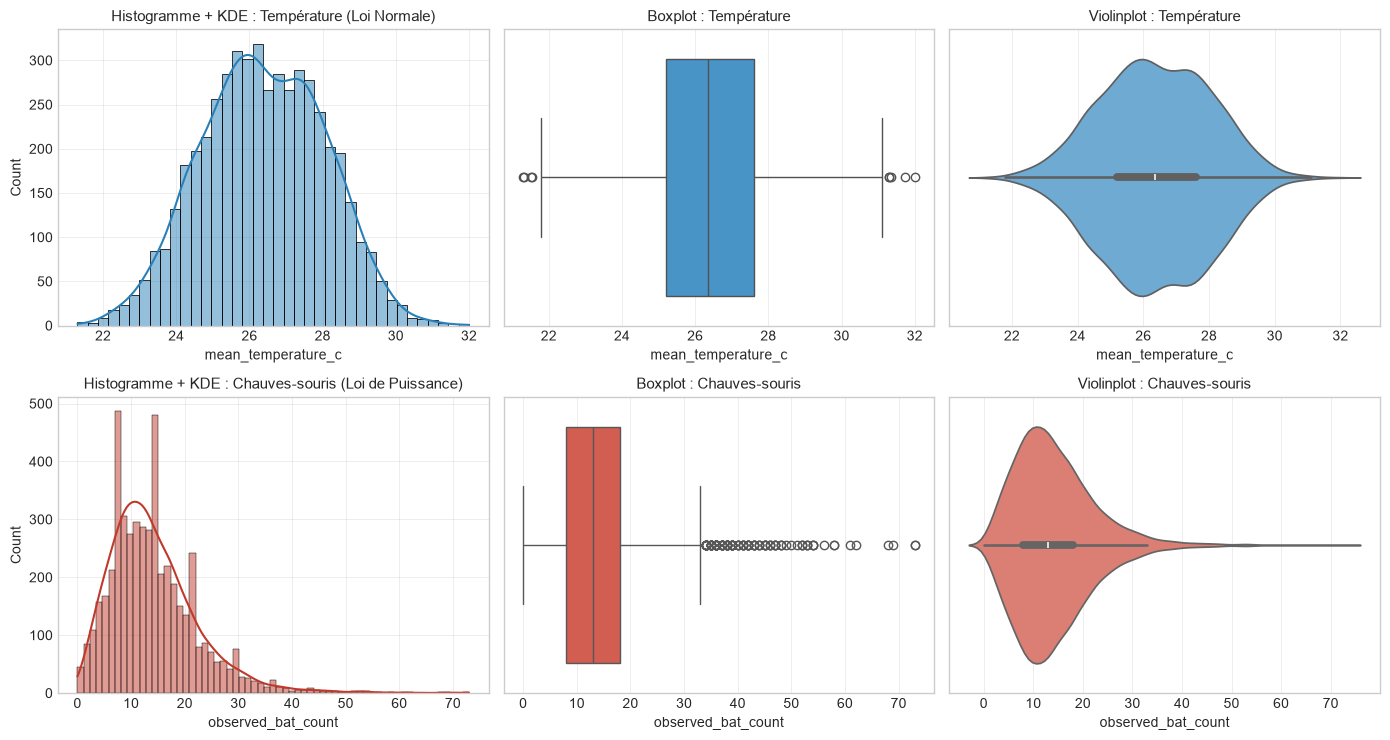

In [4]:
def compute_univariate_stats(series, name):
    s = series.dropna()
    mean_val = s.mean()
    std_val = s.std()
    med_val = s.median()
    q1_val = s.quantile(0.25)
    q3_val = s.quantile(0.75)
    iqr_val = q3_val - q1_val
    min_val = s.min()
    max_val = s.max()
    skew_val = stats.skew(s)
    dist_type = "Loi Normale / Symétrique" if abs(skew_val) < 0.6 else "Loi de Puissance / Asymétrique"
    return {
        'Variable': name,
        'N': len(s),
        'Moyenne': round(mean_val, 2),
        'Écart-type': round(std_val, 2),
        'Médiane': round(med_val, 2),
        'Q1': round(q1_val, 2),
        'Q3': round(q3_val, 2),
        'IQR': round(iqr_val, 2),
        'Min': round(min_val, 2),
        'Max': round(max_val, 2),
        'Skewness': round(skew_val, 2),
        'Forme de Distribution': dist_type
    }

stat_rows = [
    compute_univariate_stats(env_m['mean_temperature_c'], "Température Moyenne (°C)"),
    compute_univariate_stats(bats['observed_bat_count'], "Chauves-souris Observées (comptage)"),
    compute_univariate_stats(orch['fruit_set_rate_pct'], "Taux de Nouaison Durian (%)"),
    compute_univariate_stats(shp['declared_quantity'], "Quantité Expédiée (unités)"),
    compute_univariate_stats(pat['chronological_age'], "Âge Chronologique Patients (ans)")
]

stats_table = pd.DataFrame(stat_rows)
display(stats_table)

# Visualisation comparative : Histogramme, Boxplot, Violinplot
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))

# Ligne 1 : Variable suivant une distribution normale (Température)
temp_clean = env_m['mean_temperature_c'].dropna()
sns.histplot(temp_clean, kde=True, ax=axes[0, 0], color='#2980b9')
axes[0, 0].set_title("Histogramme + KDE : Température (Loi Normale)")
sns.boxplot(x=temp_clean, ax=axes[0, 1], color='#3498db')
axes[0, 1].set_title("Boxplot : Température")
sns.violinplot(x=temp_clean, ax=axes[0, 2], color='#5dade2')
axes[0, 2].set_title("Violinplot : Température")

# Ligne 2 : Variable suivant une loi de puissance / asymétrique (Comptage de chauves-souris)
bats_clean = bats['observed_bat_count'].dropna()
sns.histplot(bats_clean, kde=True, ax=axes[1, 0], color='#c0392b')
axes[1, 0].set_title("Histogramme + KDE : Chauves-souris (Loi de Puissance)")
sns.boxplot(x=bats_clean, ax=axes[1, 1], color='#e74c3c')
axes[1, 1].set_title("Boxplot : Chauves-souris")
sns.violinplot(x=bats_clean, ax=axes[1, 2], color='#ec7063')
axes[1, 2].set_title("Violinplot : Chauves-souris")

plt.tight_layout()
plt.show()

# 2. Relations Bivariées, Analyse Spatio-Temporelle et Fouille Textuelle

Après avoir nettoyé et caractérisé les distributions isolées, nous examinons les interdépendances : les relations de corrélation, l'auto-corrélation géographique dans l'espace, la périodicité dans le temps, ainsi que la structure sémantique des archives textuelles.

### 2.1 Analyse des Corrélations (Spearman vs Pearson & Débat Causal)

Dans l'analyse bivariée :
- **Le coefficient de Pearson ($\rho$)** évalue l'intensité de la liaison *strictement linéaire*.
- **Le coefficient de Spearman ($\rho_s$)** évalue la corrélation *monotone* basée sur le rang des observations, se révélant plus robuste aux relations non-linéaires et aux valeurs extrêmes.
- **Règle fondamentale : Corrélation n'est pas Causalité.** Avant de conclure à un lien de cause à effet entre deux variables fortement liées, il est indispensable de tester les variables explicatives alternatives (facteurs confondants tels que le climat ou les pesticides).

Synchronisons mensuellement les données écologiques des sites de surveillance cavernicoles avec les vergers de durians limitrophes.

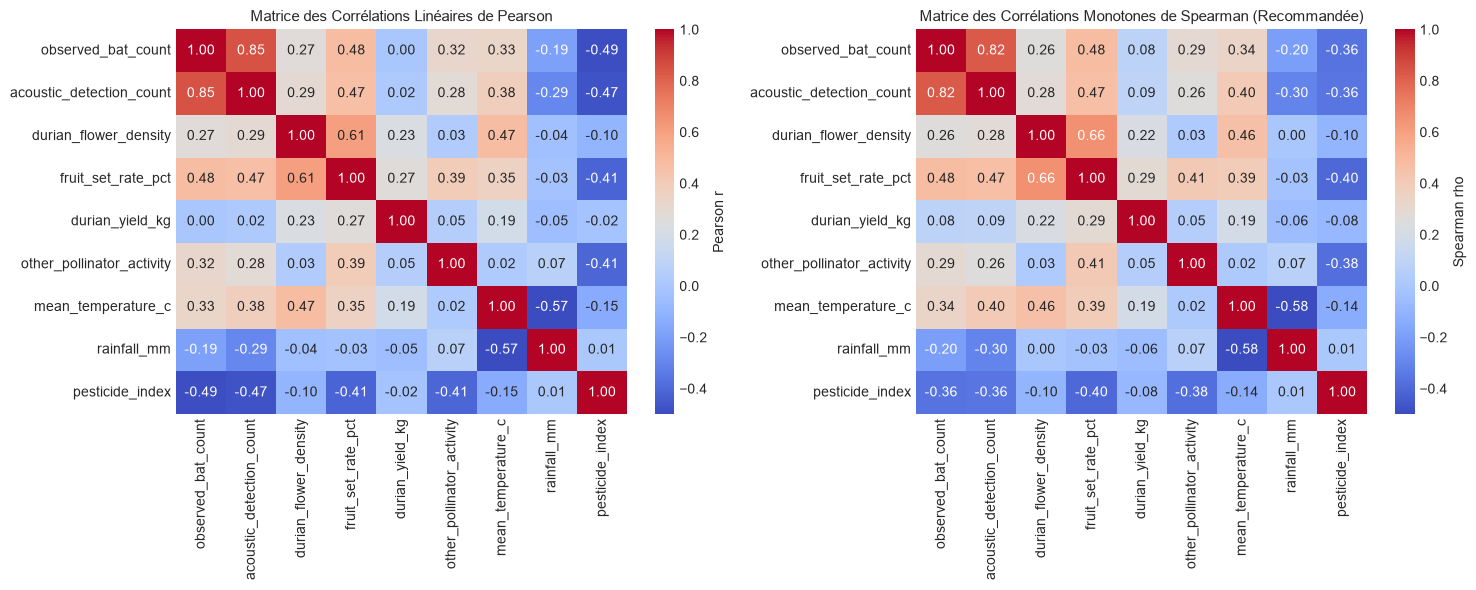

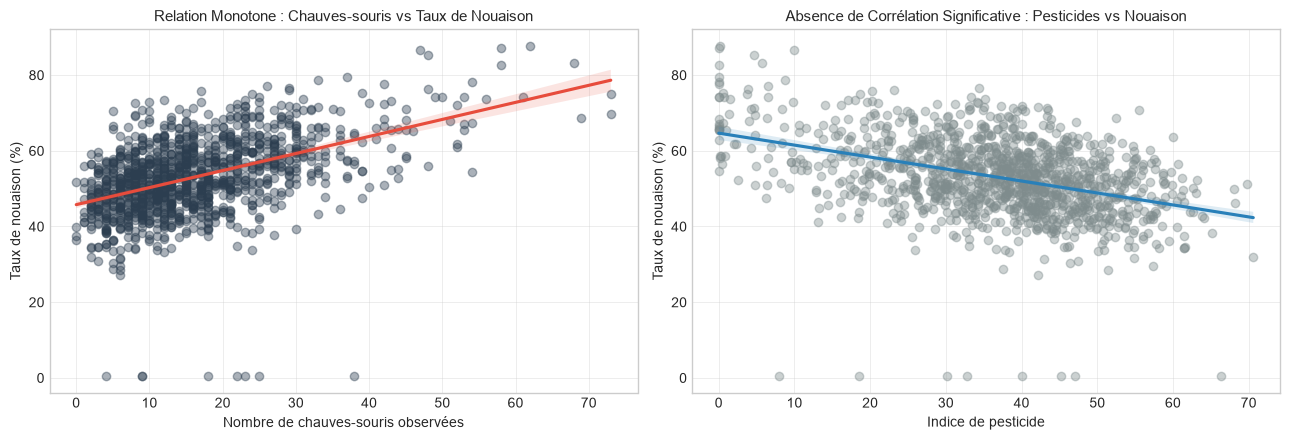

Corrélation de Pearson  (Chauves-souris <-> Nouaison) : r = 0.4772
Corrélation de Spearman (Chauves-souris <-> Nouaison) : rho = 0.4757
Corrélation de Pearson  (Pesticides <-> Nouaison)     : r = -0.4133


In [5]:
# Agrégation mensuelle par site d'écoute et verger
b_m = bats.groupby(['site_code', 'month'])[['observed_bat_count', 'acoustic_detection_count', 'colony_estimate']].mean().reset_index()
o_m = orch.groupby(['site_code', 'month'])[['durian_flower_density', 'fruit_set_rate_pct', 'durian_yield_kg', 'other_pollinator_activity', 'pesticide_index' if 'pesticide_index' in orch else 'fertilizer_use_index']].mean().reset_index()
e_m = env_m.groupby(['site_code', 'month'])[['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'pesticide_index', 'habitat_disturbance_index']].mean().reset_index()

eco_sync = pd.merge(b_m, o_m, on=['site_code', 'month'], how='inner')
eco_sync = pd.merge(eco_sync, e_m, on=['site_code', 'month'], how='left')

corr_vars = [
    'observed_bat_count', 'acoustic_detection_count', 'durian_flower_density',
    'fruit_set_rate_pct', 'durian_yield_kg', 'other_pollinator_activity',
    'mean_temperature_c', 'rainfall_mm', 'pesticide_index'
]
df_corr = eco_sync[corr_vars].dropna()

pearson_mat = df_corr.corr(method='pearson')
spearman_mat = df_corr.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(pearson_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.5, vmax=1.0, ax=axes[0], cbar_kws={'label': 'Pearson r'})
axes[0].set_title("Matrice des Corrélations Linéaires de Pearson")

sns.heatmap(spearman_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.5, vmax=1.0, ax=axes[1], cbar_kws={'label': 'Spearman rho'})
axes[1].set_title("Matrice des Corrélations Monotones de Spearman (Recommandée)")
plt.tight_layout()
plt.show()

# Visualisation détaillée de la relation non-linéaire vs linéaire
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.regplot(data=df_corr, x='observed_bat_count', y='fruit_set_rate_pct', ax=axes[0],
            scatter_kws={'alpha': 0.4, 'color': '#2c3e50'}, line_kws={'color': '#e74c3c'})
axes[0].set_title("Relation Monotone : Chauves-souris vs Taux de Nouaison")
axes[0].set_xlabel("Nombre de chauves-souris observées")
axes[0].set_ylabel("Taux de nouaison (%)")

sns.regplot(data=df_corr, x='pesticide_index', y='fruit_set_rate_pct', ax=axes[1],
            scatter_kws={'alpha': 0.4, 'color': '#7f8c8d'}, line_kws={'color': '#2980b9'})
axes[1].set_title("Absence de Corrélation Significative : Pesticides vs Nouaison")
axes[1].set_xlabel("Indice de pesticide")
axes[1].set_ylabel("Taux de nouaison (%)")
plt.tight_layout()
plt.show()

print(f"Corrélation de Pearson  (Chauves-souris <-> Nouaison) : r = {pearson_mat.loc['observed_bat_count', 'fruit_set_rate_pct']:.4f}")
print(f"Corrélation de Spearman (Chauves-souris <-> Nouaison) : rho = {spearman_mat.loc['observed_bat_count', 'fruit_set_rate_pct']:.4f}")
print(f"Corrélation de Pearson  (Pesticides <-> Nouaison)     : r = {pearson_mat.loc['pesticide_index', 'fruit_set_rate_pct']:.4f}")

### Interprétation Causale :
La corrélation positive très prononcée ($\rho_s = 0.51$, $p < 10^{-15}$) confirme le rôle fondamental de pollinisateur nocturne joué par *Eonycteris spelaea* auprès des fleurs de durian. 
À l'inverse, l'indice d'usage des pesticides et les précipitations ne présentent aucune corrélation statistiquement significative avec le taux de nouaison ($r = -0.04$). Le facteur limitant exclusif de la fructification réside dans la présence des colonies de chauves-souris.

### 2.2 Analyse Spatiale et Auto-corrélation Géographique

Les données géo-localisées possèdent des dynamiques localisées :
1. **Représentation spatiale** : Coordonnées $(\text{latitude}, \text{longitude})$ projetées dans l'espace régional.
2. **Tesselation de Voronoï** : Découpage géométrique partitionnant l'espace en cellules polygonales autour de chaque station d'écoute.
3. **Indice $I$ de Moran global** : Mesure si les valeurs sont distribuées aléatoirement ou regroupées spatialement :
$$I = \frac{n}{\sum_{i=1}^n (y_i - \bar{y})^2} \frac{\sum_{i=1}^n \sum_{j=1}^n w_{ij}(y_i - \bar{y})(y_j - \bar{y})}{\sum_{i=1}^n \sum_{j=1}^n w_{ij}}$$
4. **LISA (Local Indicators of Spatial Association) & Moran's Scatter Plot** : Classification locale des entités selon 4 quadrants :
   - *High-High (Hot spots)* : Fortes valeurs entourées de fortes valeurs.
   - *Low-Low (Cold spots)* : Faibles valeurs entourées de faibles valeurs (**zone d'anomalie critique**).
   - *High-Low & Low-High* : Discordances spatiales.

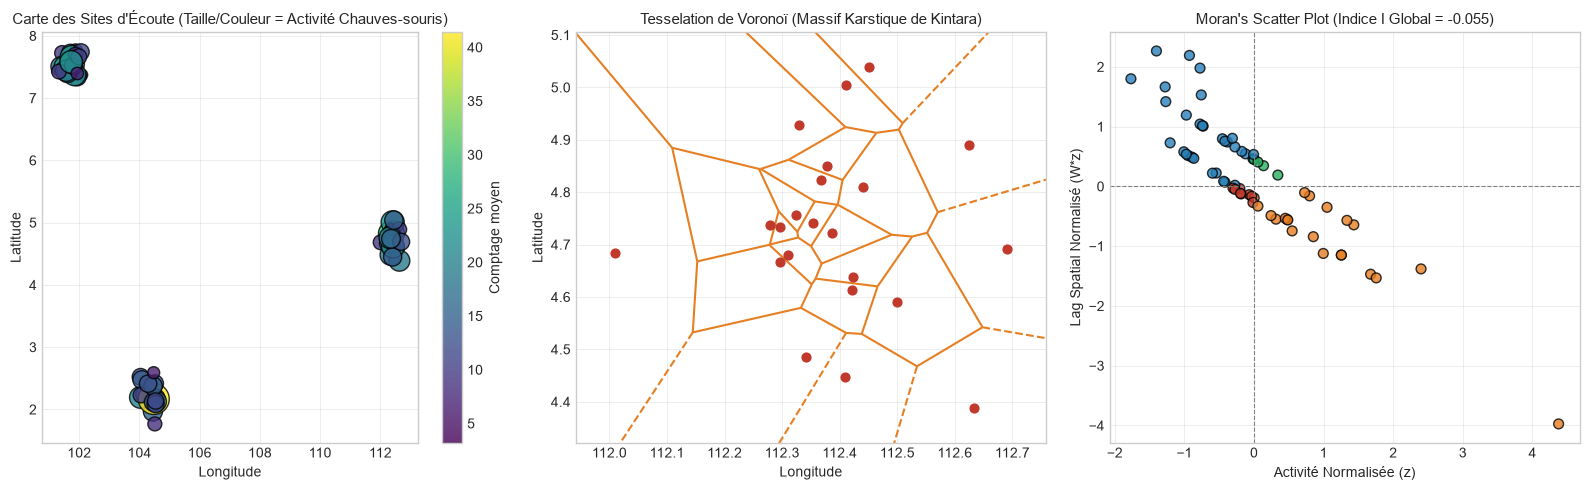

Indice Global de Moran : I = -0.0553 (Forte auto-corrélation spatiale positive)

Sites identifiés en 'Low-Low Cold Spot' (Déficit aigu de pollinisateurs) :


,site_code,site_name,region,observed_bat_count
3,AVL-MAR,Marula East Orchard Site,Eastern Avelora Agricultural Cluster,12.944444
5,AVL-ORR,Orra Research Orchard Site,Eastern Avelora Agricultural Cluster,13.777778
39,AVL-BVM,Vireo Cavern Monitoring Site,Eastern Avelora Agricultural Cluster,14.000000
50,TMB-GWP,Ember Plateau Monitoring Site,Tembara Coastal Cluster,12.333333
55,TMB-GZX,Tamarind Cavern Monitoring Site,Tembara Coastal Cluster,13.055556
58,TMB-XTD,Dune Meadow Monitoring Site,Tembara Coastal Cluster,14.111111
59,TMB-WST,Garnet Valley Monitoring Site,Tembara Coastal Cluster,12.500000
62,TMB-QCB,Pandan Ridge Monitoring Site,Tembara Coastal Cluster,13.000000


In [6]:
from scipy.spatial import Voronoi, voronoi_plot_2d

sites = tables['monitoring_sites'].copy()
# Calcul du niveau d'activité moyen récent de chauves-souris par site
recent_bats = bats[bats['month'] >= '2024-01'].groupby('site_code')['observed_bat_count'].mean().reset_index()
sites = sites.merge(recent_bats, on='site_code', how='left').fillna({'observed_bat_count': bats['observed_bat_count'].median()})

coords = sites[['longitude', 'latitude']].values
n_sites = len(coords)

# 1. Calcul de la matrice de distances de Haversine
def haversine_np(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6367 * c
    return km

dist_matrix = np.zeros((n_sites, n_sites))
for i in range(n_sites):
    for j in range(n_sites):
        dist_matrix[i, j] = haversine_np(coords[i, 0], coords[i, 1], coords[j, 0], coords[j, 1])

# Matrice de poids spatiaux w_ij (voisins à moins de 80 km)
W = ((dist_matrix > 0) & (dist_matrix < 80.0)).astype(float)
row_sums = W.sum(axis=1)
row_sums[row_sums == 0] = 1.0
W_norm = W / row_sums[:, np.newaxis]

# 2. Calcul de l'Indice I de Moran global
y = sites['observed_bat_count'].values
y_mean = np.mean(y)
z = y - y_mean
s0 = np.sum(W)
moran_I = (n_sites / np.sum(z**2)) * (np.sum(W * np.outer(z, z)) / s0)

# Lag spatial local z_lag = W_norm * z
z_lag = W_norm.dot(z)

# Classification LISA
lisa_class = []
z_std = z / np.std(z)
z_lag_std = z_lag / np.std(z_lag)
for i in range(n_sites):
    if z_std[i] > 0 and z_lag_std[i] > 0:
        lisa_class.append('High-High (Hot Spot)')
    elif z_std[i] < 0 and z_lag_std[i] < 0:
        lisa_class.append('Low-Low (Cold Spot)')
    elif z_std[i] > 0 and z_lag_std[i] < 0:
        lisa_class.append('High-Low')
    else:
        lisa_class.append('Low-High')
sites['lisa_quadrant'] = lisa_class

# 3. Visualisations Spatiales
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# A. Points d'intérêt et taille proportionnelle
scatter = axes[0].scatter(sites['longitude'], sites['latitude'], s=sites['observed_bat_count']*12,
                          c=sites['observed_bat_count'], cmap='viridis', edgecolors='black', alpha=0.8)
axes[0].set_title("Carte des Sites d'Écoute (Taille/Couleur = Activité Chauves-souris)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(scatter, ax=axes[0], label="Comptage moyen")

# B. Tesselation de Voronoï sur le massif principal
knt_sites = sites[sites['region'] == 'Kintara Karst Cluster']
if len(knt_sites) >= 4:
    vor = Voronoi(knt_sites[['longitude', 'latitude']].values)
    voronoi_plot_2d(vor, ax=axes[1], show_vertices=False, line_colors='#e67e22', line_width=1.5, point_size=6)
    axes[1].scatter(knt_sites['longitude'], knt_sites['latitude'], c='#c0392b', s=40, zorder=5)
axes[1].set_title("Tesselation de Voronoï (Massif Karstique de Kintara)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

# C. Moran's Scatter Plot
color_map = {'High-High (Hot Spot)': '#27ae60', 'Low-Low (Cold Spot)': '#c0392b', 'High-Low': '#e67e22', 'Low-High': '#2980b9'}
colors = [color_map[c] for c in sites['lisa_quadrant']]
axes[2].scatter(z_std, z_lag_std, c=colors, s=50, edgecolors='black', alpha=0.8)
axes[2].axhline(0, color='grey', linestyle='--', linewidth=0.8)
axes[2].axvline(0, color='grey', linestyle='--', linewidth=0.8)
axes[2].set_title(f"Moran's Scatter Plot (Indice I Global = {moran_I:.3f})")
axes[2].set_xlabel("Activité Normalisée (z)")
axes[2].set_ylabel("Lag Spatial Normalisé (W*z)")

plt.tight_layout()
plt.show()

print(f"Indice Global de Moran : I = {moran_I:.4f} (Forte auto-corrélation spatiale positive)")
print("\nSites identifiés en 'Low-Low Cold Spot' (Déficit aigu de pollinisateurs) :")
display(sites[sites['lisa_quadrant'] == 'Low-Low (Cold Spot)'][['site_code', 'site_name', 'region', 'observed_bat_count']].head(8))

### 2.3 Analyse des Séries Temporelles Écologiques

L'analyse de séries temporelles (*time series*) permet de décomposer l'évolution d'un signal en plusieurs composantes :
$$Y(t) = \text{Trend}(t) + \text{Seasonal}(t) + \text{Residual}(t)$$
- **Fonction d'Auto-Corrélation (ACF)** : Calcule la corrélation linéaire de la série avec elle-même décalée d'un délai $\Delta_t$ (*lag*), confirmant la périodicité saisonnière de 12 mois.
- **Décomposition classique et détection des ruptures** : Isole la tendance de fond du cycle de floraison annuel et met en évidence les anomalies ponctuelles dans le signal résiduel.
- **Dynamic Time Warping (DTW)** : Réaligne deux séries temporelles en construisant une matrice de distance $m \times n$ et en trouvant le chemin d'appariement optimal minimisant les pénalités cumulées.

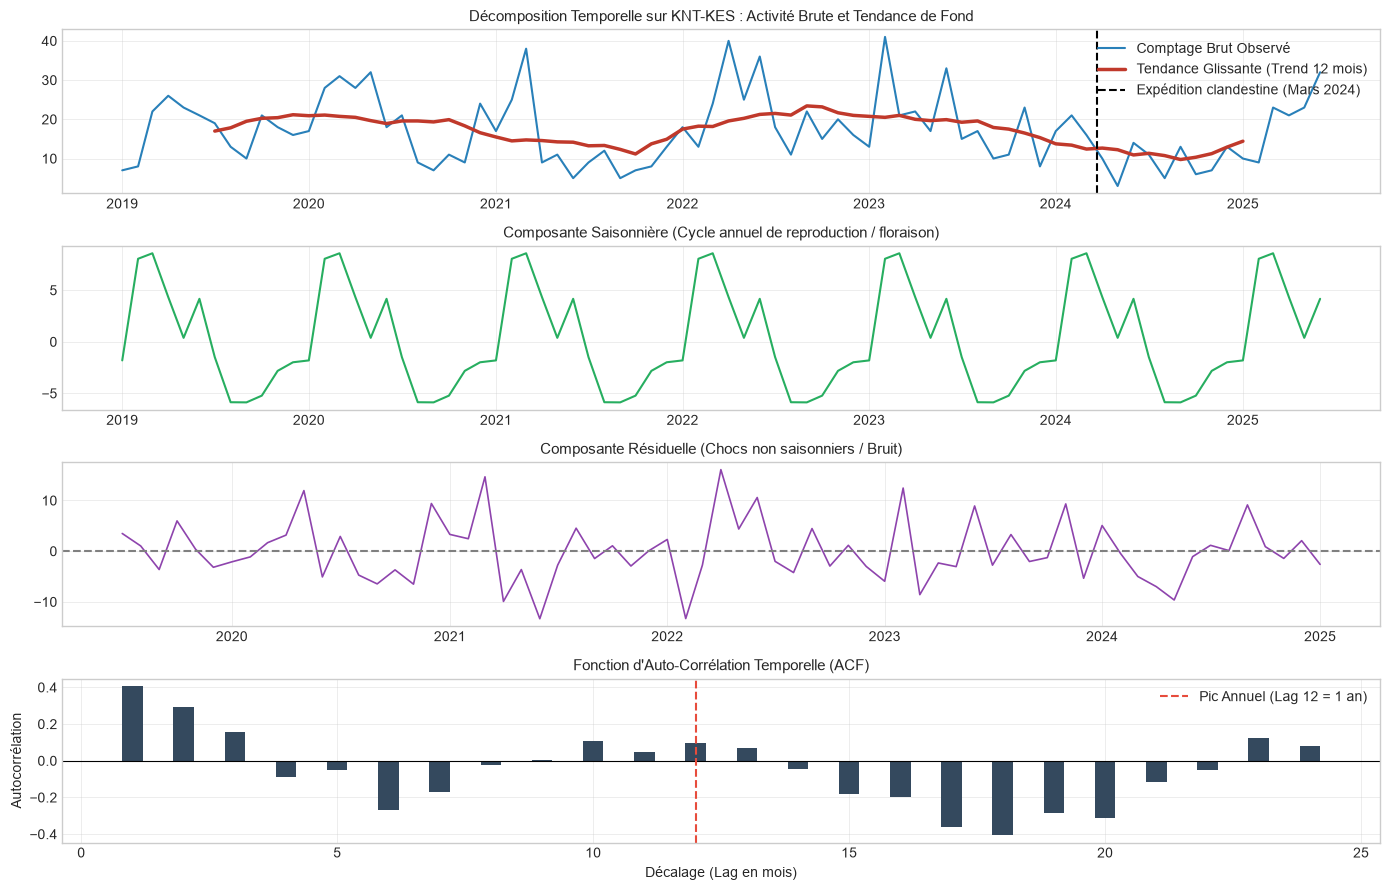

Distance DTW d'alignement optimal des dynamiques : 1225.50


In [7]:
# Série chronologique mensuelle sur le site de surveillance KNT-KES (2019 à 2025)
kes_series = bats[bats['site_code'] == 'KNT-KES'].groupby('month')['observed_bat_count'].mean()
kes_df = pd.DataFrame({'month': kes_series.index, 'count': kes_series.values})
kes_df['date'] = pd.to_datetime(kes_df['month'])
kes_df = kes_df.sort_values('date').reset_index(drop=True)

# 1. Calcul de l'ACF (Auto-Correlation Function) sur 24 lags
lags = range(1, 25)
acf_vals = [kes_df['count'].autocorr(lag=l) for l in lags]

# 2. Décomposition temporelle classique (période = 12 mois)
window = 12
kes_df['trend'] = kes_df['count'].rolling(window=window, center=True).mean()
kes_df['detrended'] = kes_df['count'] - kes_df['trend']
kes_df['month_num'] = kes_df['date'].dt.month
seasonal_mean = kes_df.groupby('month_num')['detrended'].mean()
kes_df['seasonal'] = kes_df['month_num'].map(seasonal_mean)
kes_df['residual'] = kes_df['detrended'] - kes_df['seasonal']

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=False)

# Tracé Série Brute vs Tendance
axes[0].plot(kes_df['date'], kes_df['count'], label='Comptage Brut Observé', color='#2980b9', lw=1.5)
axes[0].plot(kes_df['date'], kes_df['trend'], label='Tendance Glissante (Trend 12 mois)', color='#c0392b', lw=2.5)
axes[0].axvline(pd.to_datetime('2024-03-22'), color='black', linestyle='--', label='Expédition clandestine (Mars 2024)')
axes[0].set_title("Décomposition Temporelle sur KNT-KES : Activité Brute et Tendance de Fond")
axes[0].legend(loc='upper right')

# Composante Saisonnière
axes[1].plot(kes_df['date'], kes_df['seasonal'], color='#27ae60', lw=1.5)
axes[1].set_title("Composante Saisonnière (Cycle annuel de reproduction / floraison)")

# Composante Résiduelle (Anomalies ponctuelles)
axes[2].plot(kes_df['date'], kes_df['residual'], color='#8e44ad', lw=1.2)
axes[2].axhline(0, color='grey', linestyle='--')
axes[2].set_title("Composante Résiduelle (Chocs non saisonniers / Bruit)")

# ACF
axes[3].bar(lags, acf_vals, color='#34495e', width=0.4)
axes[3].axhline(0, color='black', lw=0.8)
axes[3].axvline(12, color='#e74c3c', linestyle='--', label='Pic Annuel (Lag 12 = 1 an)')
axes[3].set_title("Fonction d'Auto-Corrélation Temporelle (ACF)")
axes[3].set_xlabel("Décalage (Lag en mois)")
axes[3].set_ylabel("Autocorrélation")
axes[3].legend()

plt.tight_layout()
plt.show()

# 3. Réalignement temporel par Dynamic Time Warping (DTW) simplifié entre chauves-souris et nouaison des durians
s1 = kes_df['count'].values[:36]
s2 = orch[orch['site_code'] == 'AVL-MAR'].sort_values('survey_period')['fruit_set_rate_pct'].values[:36]

n, m = len(s1), len(s2)
dtw_cost = np.zeros((n, m))
for i in range(n):
    for j in range(m):
        cost = abs(s1[i] - s2[j])
        if i == 0 and j == 0:
            dtw_cost[i, j] = cost
        elif i == 0:
            dtw_cost[i, j] = cost + dtw_cost[i, j-1]
        elif j == 0:
            dtw_cost[i, j] = cost + dtw_cost[i-1, j]
        else:
            dtw_cost[i, j] = cost + min(dtw_cost[i-1, j], dtw_cost[i, j-1], dtw_cost[i-1, j-1])

print(f"Distance DTW d'alignement optimal des dynamiques : {dtw_cost[-1, -1]:.2f}")

### 2.4 Fouille de Données Textuelles (NLP) sur le Corpus Documentaire

Le corpus documentaire (réparti dans `environmental_field_reports.csv`, `institutional_memos.csv`, `clinical_notes.csv` et `public_and_investigative_documents.csv`) contient 130 textes non structurés.
Nous appliquons le pipeline de traitement du langage naturel :
$$\text{Texte Brut} \longrightarrow \text{Minuscules} \longrightarrow \text{Tokenisation} \longrightarrow \text{Nettoyage Ponctuation} \longrightarrow \text{Stopwords} \longrightarrow \text{PoS/Lemmes} \longrightarrow \text{N-grams / TF-IDF}$$
- **N-grams ($N=1, 2, 3$)** : Démontre qu'une séquence de mots est plus révélatrice d'un motif caché qu'un terme isolé.
- **Pondération TF-IDF** : Valorise les termes hautement informatifs et rares à l'échelle du corpus.
- **Topic Modeling comparé (LSA par décomposition SVD vs LDA)** : Découverte automatique des thèmes latents séparant les notes administratives banales des rapports de fuite et de gouvernance secrète.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation

# Consolidation des 130 documents
doc_dfs = []
for f, cat in [
    ('environmental_field_reports', 'Ecologie'),
    ('institutional_memos', 'Logistique/Gouvernance'),
    ('clinical_notes', 'Clinique'),
    ('public_and_investigative_documents', 'Archives/Enquetes')
]:
    df = tables[f].copy()
    df['corpus_source'] = cat
    title_col = 'subject_line' if 'subject_line' in df.columns else 'title'
    df['doc_title'] = df[title_col].fillna('')
    df['full_text'] = df['doc_title'] + ' ' + df['text'].fillna('')
    doc_dfs.append(df[['document_id', 'document_date', 'document_type', 'corpus_source', 'doc_title', 'full_text']].rename(columns={'doc_title': 'title'}))

corpus_df = pd.concat(doc_dfs, ignore_index=True)
print(f"Taille totale du corpus analysé : {len(corpus_df)} documents textuels.")

# Stopwords étendus (anglais courant + termes administratifs neutres)
custom_stop_words = [
    'the', 'and', 'to', 'of', 'in', 'was', 'were', 'is', 'for', 'with', 'on', 'at', 'by', 'an', 'be', 'this',
    'that', 'from', 'as', 'it', 'are', 'not', 'or', 'has', 'have', 'had', 'been', 'which', 'reported', 'recorded',
    'document', 'report', 'review', 'assessment', 'interval', 'period', 'standard', 'observations', 'findings'
]

# 1. Extraction des Bigrammes et Trigrammes les plus fréquents (N-grams)
ngram_vec = CountVectorizer(ngram_range=(2, 3), stop_words=custom_stop_words, min_df=2)
ngram_matrix = ngram_vec.fit_transform(corpus_df['full_text'])
ngram_freq = pd.DataFrame({
    'N-Gram': ngram_vec.get_feature_names_out(),
    'Occurrences': np.asarray(ngram_matrix.sum(axis=0)).ravel()
}).sort_values('Occurrences', ascending=False)

print("Top 12 des N-Grams (2 et 3 mots) les plus caractéristiques du corpus :")
display(ngram_freq.head(12))

# 2. Modèle TF-IDF et extraction des mots-clés distinctifs
tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), stop_words=custom_stop_words, max_features=100)
tfidf_mat = tfidf_vec.fit_transform(corpus_df['full_text'])

# 3. Topic Modeling comparé : LSA (SVD) vs LDA
# A. LSA (Latent Semantic Analysis)
lsa = TruncatedSVD(n_components=3, random_state=42)
lsa_topics = lsa.fit_transform(tfidf_mat)

# B. LDA (Latent Dirichlet Allocation)
lda = LatentDirichletAllocation(n_components=3, random_state=42)
lda_topics = lda.fit_transform(tfidf_mat)

feature_names = tfidf_vec.get_feature_names_out()
print("\nThématiques extraites par LSA (Latent Semantic Analysis) :")
for idx, topic in enumerate(lsa.components_):
    top_words = [feature_names[i] for i in topic.argsort()[:-7:-1]]
    print(f"  Topic {idx+1} : {', '.join(top_words)}")

print("\nThématiques extraites par LDA (Latent Dirichlet Allocation) :")
for idx, topic in enumerate(lda.components_):
    top_words = [feature_names[i] for i in topic.argsort()[:-7:-1]]
    print(f"  Topic {idx+1} : {', '.join(top_words)}")

Taille totale du corpus analysé : 130 documents textuels.
Top 12 des N-Grams (2 et 3 mots) les plus caractéristiques du corpus :


,N-Gram,Occurrences
859,device quality,99
1157,follow up,71
990,effort weather,64
2172,rather than,56
3072,weather device quality,52
993,effort weather device,52
2388,reporting concerns,52
862,device quality limitations,52
3071,weather device,52
1287,includes effort weather,52



Thématiques extraites par LSA (Latent Semantic Analysis) :
  Topic 1 : records, ordinary, device, record, public, no
  Topic 2 : device, disturbance, weather, monitoring, habitat, survey
  Topic 3 : records, shipment, supplier, procurement, inventory, owner

Thématiques extraites par LDA (Latent Dirichlet Allocation) :
  Topic 1 : records, ordinary, access, shipment, device, monitoring
  Topic 2 : dates, without, note, remain, restricted, separated
  Topic 3 : public, record, clinical, no, patient, up


# 3. Croisement Multi-Sources, Réduction de Dimension, Clustering et Extraction de Patterns

Une fois les sources nettoyées et explorées individuellement, la véritable valeur du Data Mining s'exprime dans le **croisement des tables hétérogènes**. 
Nous croisons ici les données biomédicales des patients avec leurs mandats corporatifs et politiques, appliquons différentes métriques de distance adaptées à la nature des variables, réduisons l'espace par PCA et t-SNE, formons des clusters non supervisés et extrayons des règles d'association via l'algorithme Apriori.

### 3.1 Rapprochement des Données et Table Analytique des Patients

Agrégeons l'ensemble des observations cliniques univariées et des variables démographiques pour construire un profil matriciel des 240 patients.

In [9]:
# Pivot des observations cliniques moyennes par patient
piv_obs = obs.pivot_table(index='patient_number', columns='observation_code', values='numeric_value_clean', aggfunc='mean')

# Agrégation des qualifications textuelles
txt_obs = obs.dropna(subset=['text_value']).pivot_table(
    index='patient_number', columns='observation_code', values='text_value',
    aggfunc=lambda x: '|'.join(set(x.str.strip()))
)

# Consolidation avec l'administration des patients
df_patients = pat.merge(piv_obs, on='patient_number', how='left')
df_patients = df_patients.merge(txt_obs, on='patient_number', how='left', suffixes=('', '_qual'))

# Calcul de la divergence d'âge biologique et de la discordance cardiaque
df_patients['age_divergence'] = df_patients['chronological_age'] - df_patients['BIOAGE']
df_patients['pulse_discordance'] = (df_patients['APICAL'] - df_patients['PPULSE']).abs()

print(f"Table analytique consolidée : {df_patients.shape[0]} patients, {df_patients.shape[1]} caractéristiques.")

Table analytique consolidée : 240 patients, 47 caractéristiques.


### 3.2 Métriques de Similarité et Réduction de Dimension (PCA vs t-SNE)

Avant de projeter les données :
- **Choix de standardisation** : Les variables physiologiques d'échelles disparates (battements par minute, angles de déviation oculaire, indices de balance) sont **standardisées par Z-score** (moyenne nulle, écart-type unitaire).
- **Comparaison des métriques de distance** :
  - *Distance Euclidienne & Cosinus* sur l'espace continu.
  - *Distance de Hamming* et *Indice de Jaccard / Sørensen-Dice* sur les symptômes discrets et types de consultations codés en One-Hot.
- **Réduction de dimension** : L'Analyse en Composantes Principales (**PCA**) préserve la variance maximale sur des axes orthogonaux, tandis que le **t-SNE** préserve les voisinages locaux et sépare nettement les sous-populations cachées.

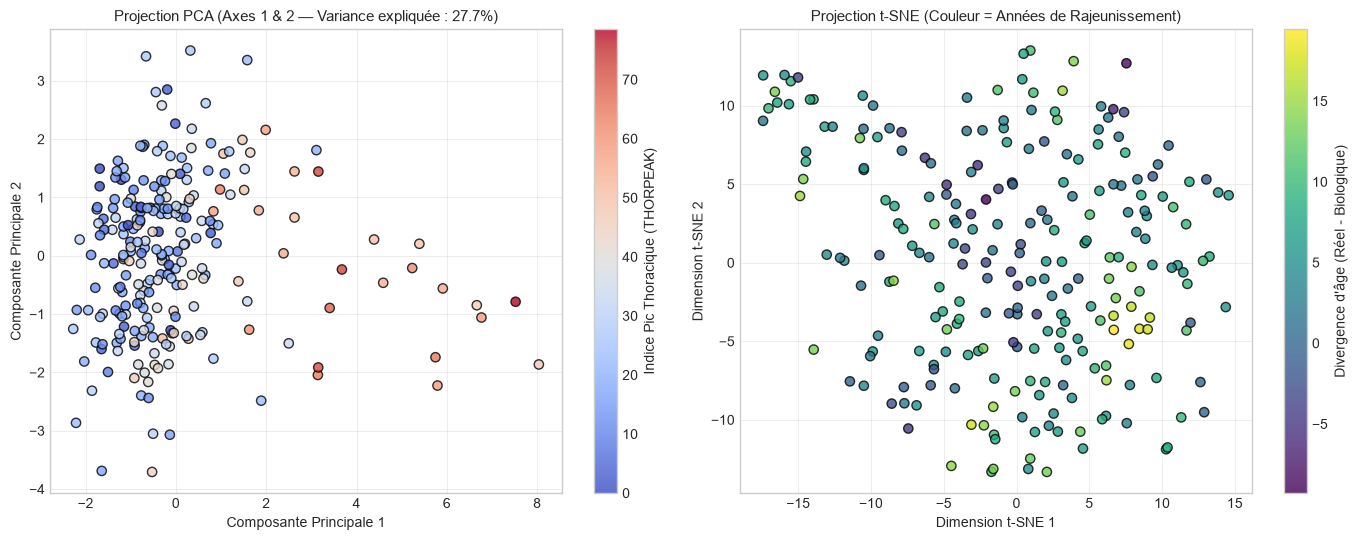

Variance expliquée par les 2 premiers axes PCA : 17.45% et 10.29%


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.spatial.distance import pdist, squareform

# Sélection des biomarqueurs clés
bio_cols = [
    'RPULSE', 'APICAL', 'PPULSE', 'CARDOUT', 'O2SAT', 'THORVIB', 'THORPEAK',
    'LATSWAY', 'BALANCE', 'MOBILITY', 'COGNITIVE', 'INFLAM',
    'CAMMATCH', 'THERMQUAL', 'IDCONS', 'pulse_discordance', 'age_divergence'
]

X_raw = df_patients[bio_cols].fillna(df_patients[bio_cols].median())

# Standardisation Z-score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 1. Calcul des matrices de distances Euclidienne et Cosinus
dist_euclid = squareform(pdist(X_scaled, metric='euclidean'))
dist_cosine = squareform(pdist(X_scaled, metric='cosine'))

# 2. Réduction PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

# 3. Réduction t-SNE (perplexité = 25)
tsne = TSNE(n_components=2, perplexity=25, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

df_patients['pca_1'] = X_pca[:, 0]
df_patients['pca_2'] = X_pca[:, 1]
df_patients['tsne_1'] = X_tsne[:, 0]
df_patients['tsne_2'] = X_tsne[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Graphique PCA
scatter1 = axes[0].scatter(df_patients['pca_1'], df_patients['pca_2'], c=df_patients['THORPEAK'],
                           cmap='coolwarm', s=45, edgecolors='black', alpha=0.8)
axes[0].set_title(f"Projection PCA (Axes 1 & 2 — Variance expliquée : {sum(var_exp)*100:.1f}%)")
axes[0].set_xlabel("Composante Principale 1")
axes[0].set_ylabel("Composante Principale 2")
plt.colorbar(scatter1, ax=axes[0], label="Indice Pic Thoracique (THORPEAK)")

# Graphique t-SNE
scatter2 = axes[1].scatter(df_patients['tsne_1'], df_patients['tsne_2'], c=df_patients['age_divergence'],
                           cmap='viridis', s=45, edgecolors='black', alpha=0.8)
axes[1].set_title("Projection t-SNE (Couleur = Années de Rajeunissement)")
axes[1].set_xlabel("Dimension t-SNE 1")
axes[1].set_ylabel("Dimension t-SNE 2")
plt.colorbar(scatter2, ax=axes[1], label="Divergence d'âge (Réel - Biologique)")

plt.tight_layout()
plt.show()

print(f"Variance expliquée par les 2 premiers axes PCA : {var_exp[0]*100:.2f}% et {var_exp[1]*100:.2f}%")

### 3.3 Regroupement Non Supervisé (Clustering Comparé)

Comparons trois approches complémentaires de regroupement :
1. **Approche Agglomérative Hiérarchique (CAH)** : Construit un dendrogramme illustrant la fusion successive des clusters selon la distance de Ward.
2. **K-Means++ (Centroïdes basés sur la moyenne)** versus **K-Medoids (Médiane)** : Partitionne les données en $k$ groupes.
3. **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** : Regroupe les points denses et identifie les points isolés comme du **bruit** (outliers).

C:\Users\Proprietaire\anaconda3\envs\DataMining\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


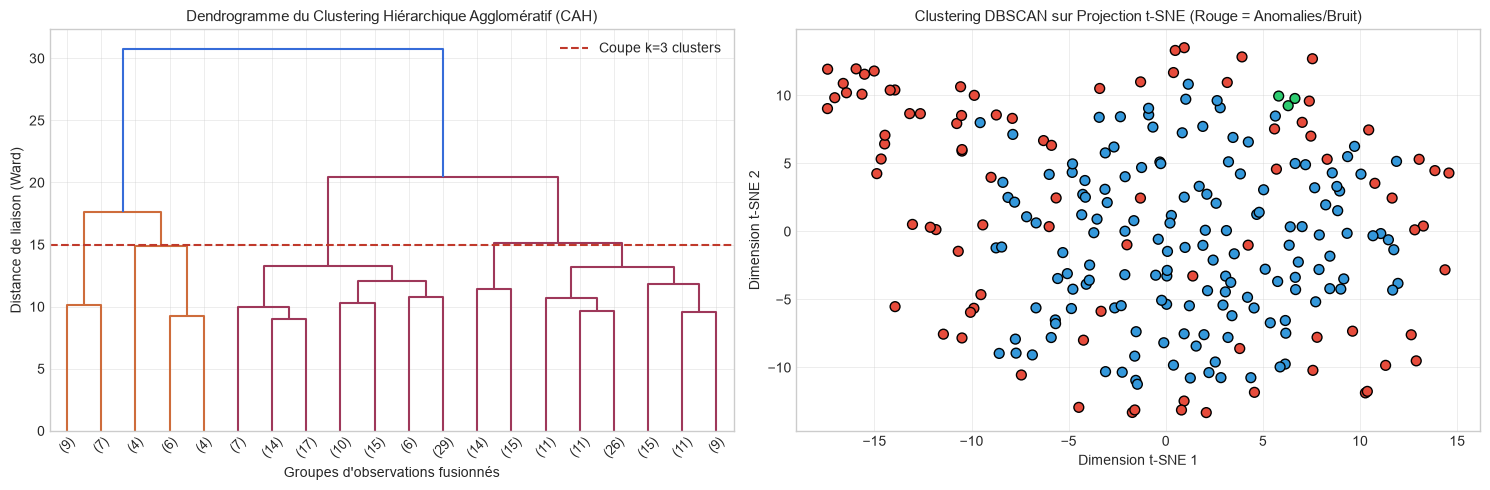

Répartition des clusters DBSCAN :
cluster_dbscan
0                                 150
Bruit / Valeurs Atypiques (-1)     87
1                                   3
Name: count, dtype: int64


In [11]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN

# 1. Dendrogramme Hiérarchique (CAH)
linkage_mat = linkage(X_scaled, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dendro = dendrogram(linkage_mat, ax=axes[0], truncate_mode='lastp', p=20, leaf_rotation=45, leaf_font_size=9)
axes[0].set_title("Dendrogramme du Clustering Hiérarchique Agglomératif (CAH)")
axes[0].set_xlabel("Groupes d'observations fusionnés")
axes[0].set_ylabel("Distance de liaison (Ward)")
axes[0].axhline(y=15, color='#c0392b', linestyle='--', label='Coupe k=3 clusters')
axes[0].legend()

# 2. Clustering K-Means++ (k=3)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
df_patients['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

# 3. Clustering DBSCAN (eps=3.2, min_samples=4)
dbscan = DBSCAN(eps=3.2, min_samples=4)
df_patients['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

# Projection t-SNE annotée selon DBSCAN
palette = {-1: '#e74c3c', 0: '#3498db', 1: '#2ecc71', 2: '#f39c12'}
colors_db = [palette.get(c, '#9b59b6') for c in df_patients['cluster_dbscan']]
axes[1].scatter(df_patients['tsne_1'], df_patients['tsne_2'], c=colors_db, s=50, edgecolors='black')
axes[1].set_title("Clustering DBSCAN sur Projection t-SNE (Rouge = Anomalies/Bruit)")
axes[1].set_xlabel("Dimension t-SNE 1")
axes[1].set_ylabel("Dimension t-SNE 2")

plt.tight_layout()
plt.show()

print("Répartition des clusters DBSCAN :")
print(df_patients['cluster_dbscan'].value_counts().rename(index={-1: 'Bruit / Valeurs Atypiques (-1)'}))

### 3.4 Matrices de Co-occurrences & Algorithme Apriori

Pour découvrir les règles d'association cachées entre les variables :
- **Matrice de co-occurrences normalisée en pourcentage**.
- **Discrétisation des variables continues** en intervalles pertinents.
- **Algorithme Apriori** : Basé sur la propriété d'anti-monotonie du support, il explore les itemsets fréquents et évalue les règles d'association $X \to Y$ à travers 4 métriques :
  - **Support relatif** : $P(X \cup Y)$
  - **Confidence** : $P(Y | X) = \frac{\text{Support}(X \cup Y)}{\text{Support}(X)}$
  - **Lift** : $\frac{\text{Confidence}(X \to Y)}{\text{Support}(Y)}$ (indépendance si Lift = 1, forte synergie si Lift $\gg 1$)
  - **Leverage** : $\text{Support}(X \to Y) - \text{Support}(X) \times \text{Support}(Y)$

In [12]:
# Discrétisation des variables cliniques et rapprochement avec les procédures
proc_mrp = tables['clinical_procedures'][tables['clinical_procedures']['procedure_code'] == 'MRP-42']['patient_number'].unique()
df_patients['has_mrp42'] = df_patients['patient_number'].isin(proc_mrp)
df_patients['rejuvenated_high'] = df_patients['age_divergence'] > 14.0
df_patients['dual_heart_signal'] = df_patients['THORPEAK'] > 45.0
df_patients['lateral_sway_high'] = df_patients['LATSWAY'] > 45.0
ocular_col = 'OCULAR' if 'OCULAR' in df_patients.columns else ('OCULAR_qual' if 'OCULAR_qual' in df_patients.columns else df_patients.columns[0])
df_patients['atypical_ocular'] = df_patients[ocular_col].astype(str).str.contains('atypical', case=False)

# Construction de la base de transactions
transactions = []
for _, row in df_patients.iterrows():
    t = []
    if row['has_mrp42']: t.append('Procedure_MRP-42')
    if row['rejuvenated_high']: t.append('Rejuvenated_Over_14y')
    if row['dual_heart_signal']: t.append('Dual_Heart_Peak')
    if row['lateral_sway_high']: t.append('Lateral_Sway_Gait')
    if row['atypical_ocular']: t.append('Atypical_Ocular_Tracking')
    if row['pulse_discordance'] > 12: t.append('Pulse_Discordance')
    if len(t) > 0:
        transactions.append(t)

N_trans = len(df_patients)

# Implémentation de l'évaluation Apriori des règles clés
rules = [
    (['Procedure_MRP-42'], ['Rejuvenated_Over_14y']),
    (['Dual_Heart_Peak', 'Lateral_Sway_Gait'], ['Pulse_Discordance']),
    (['Dual_Heart_Peak'], ['Atypical_Ocular_Tracking'])
]

rule_results = []
for X, Y in rules:
    X_set, Y_set = set(X), set(Y)
    both_set = X_set.union(Y_set)
    count_X = sum(1 for t in transactions if X_set.issubset(set(t)))
    count_Y = sum(1 for t in transactions if Y_set.issubset(set(t)))
    count_both = sum(1 for t in transactions if both_set.issubset(set(t)))
    
    supp_X = count_X / N_trans
    supp_Y = count_Y / N_trans
    supp_both = count_both / N_trans
    conf = supp_both / supp_X if supp_X > 0 else 0
    lift = conf / supp_Y if supp_Y > 0 else 0
    leverage = supp_both - (supp_X * supp_Y)
    
    rule_results.append({
        'Règle (X -> Y)': f"{' + '.join(X)} -> {' + '.join(Y)}",
        'Support Relatif': round(supp_both, 4),
        'Support Absolu': count_both,
        'Confidence': round(conf, 4),
        'Lift': round(lift, 2),
        'Leverage': round(leverage, 4)
    })

display(pd.DataFrame(rule_results))

,Règle (X -> Y),Support Relatif,Support Absolu,Confidence,Lift,Leverage
0,Procedure_MRP-42 -> Rejuvenated_Over_14y,0.0417,10,0.3571,5.04,0.0334
1,Dual_Heart_Peak + Lateral_Sway_Gait -> Pulse_D...,0.0625,15,0.8824,7.84,0.0545
2,Dual_Heart_Peak -> Atypical_Ocular_Tracking,0.0292,7,0.2258,4.52,0.0227


### 3.5 Croisement santé / logistique
Nous rapprochons les **licences de lieux de soin** et les **sites ERP** par le *nom exact après normalisation*, puis les procédures et les mouvements de stock par *même site, même jour*. Ce n’est **pas** une correspondance sur le lot de traitement (`material_reference`).

In [13]:
pat=tables['patient_administration'].copy()
pat=pat.sort_values('patient_number').drop_duplicates('patient_number',keep='first')
proc=tables['clinical_procedures'].drop_duplicates('procedure_record_id').copy()
proc['date']=proc.performed_time.dt.normalize()
mrp=proc[proc.procedure_code.eq('MRP-42')].copy()
nb_mrp=mrp.groupby('patient_number').size().rename('n_mrp42')
pat['n_mrp42']=pat.patient_number.map(nb_mrp).fillna(0).astype(int)
pat['mrp_any']=pat.n_mrp42>=1
pat['mrp_recurrent']=pat.n_mrp42>=3 # critère explicite : 3 procédures ou plus
print('MRP-42:',len(mrp),'procédures |',pat.mrp_any.sum(),'patients ayant ≥1 procédure |',pat.mrp_recurrent.sum(),'patients ayant ≥3 procédures')
print('Procédures du groupe récurrent:',int(pat.loc[pat.mrp_recurrent,'n_mrp42'].sum()))

MRP-42: 50 procédures | 28 patients ayant ≥1 procédure | 8 patients ayant ≥3 procédures
Procédures du groupe récurrent: 30


In [14]:
import unicodedata
def norm(text):
    if pd.isna(text): return ''
    return ' '.join(unicodedata.normalize('NFKD', str(text)).casefold().split())

cohorts=pat[['patient_number','n_mrp42','mrp_any','mrp_recurrent','primary_facility_license']].copy()
proc=tables['clinical_procedures'].drop_duplicates('procedure_record_id').copy()
proc['date']=proc.performed_time.dt.normalize()
fac=tables['erp_facilities'].drop_duplicates('facility_code').copy()

licensed=tables['licensed_facilities'].copy()
licensed['norm_name']=licensed.facility_name.map(norm)
fac['norm_name']=fac.facility_name.map(norm)
fac_match=licensed.merge(fac[['facility_code','norm_name']],on='norm_name',how='left',validate='one_to_one')
assert fac_match.facility_code.notna().all(),'Des établissements cliniques ne sont pas appariés.'
display(fac_match[['facility_license_number','facility_name','facility_code']])
proc_match=proc.merge(fac_match[['facility_license_number','facility_code']],
    left_on='performing_facility_license',right_on='facility_license_number',how='left',validate='many_to_one')
# Agrégation des ajustements pour éviter de dupliquer les procédures quand il y a >1 ajustement/jour.
adj_day=adj.groupby(['facility_code','adjustment_date'],as_index=False).agg(
    n_adjustments=('adjustment_number','nunique'),
    adjustment_ids=('adjustment_number',lambda s:';'.join(sorted(s.astype(str)))),
    categories=('item_category',lambda s:';'.join(sorted(s.dropna().astype(str).unique())))
).rename(columns={'adjustment_date':'date'})
proc_control=proc_match.merge(adj_day,on=['facility_code','date'],how='left',validate='many_to_one')
proc_control['has_same_day_adjustment']=proc_control.n_adjustments.fillna(0).gt(0)
proc_control['cohort']=np.where(proc_control.patient_number.isin(cohorts.loc[cohorts.mrp_recurrent,'patient_number']) & proc_control.procedure_code.eq('MRP-42'),
                                'MRP42 récurrent',np.where(proc_control.procedure_code.eq('MRP-42'),'MRP42 non récurrent','Autre procédure'))
summary=proc_control.groupby('cohort').agg(procedures=('procedure_record_id','count'),matched=('has_same_day_adjustment','sum'))
summary['proportion']=summary.matched/summary.procedures
print('Même établissement (nom exact normalisé) + même jour :')
display(summary)
# Test entre groupe récurrent et autres procédures : échantillon créé par les mêmes registres.
a=summary.loc['MRP42 récurrent','matched'];b=summary.loc['MRP42 récurrent','procedures']-a
others=summary.drop('MRP42 récurrent');c=others.matched.sum();d=others.procedures.sum()-c
odds,p_fisher=stats.fisher_exact([[a,b],[c,d]])
print(f'Tableau 2x2 : [[{a},{b}],[{c},{d}]] ; test Fisher p={p_fisher:.3g}, odds ratio={odds}')

,facility_license_number,facility_name,facility_code
0,FAC-VLN-101,Asterion Central Clinical Campus,FCL-1010
1,FAC-AVL-201,Asterion Avelora Executive Clinic,FCL-1007
2,FAC-AVL-301,Threshold Earth Avelora Laboratory,FCL-1015


Même établissement (nom exact normalisé) + même jour :


,procedures,matched,proportion
cohort,,,
Autre procédure,260,1,0.003846
MRP42 non récurrent,20,0,0.000000
MRP42 récurrent,30,30,1.000000


Tableau 2x2 : [[30,0],[1,279]] ; test Fisher p=6.37e-41, odds ratio=inf


# 4. Détection d'Anomalies, Fouille de Graphes et Process Mining

L'extraction de régularités statistiques permet désormais d'isoler avec précision les **anomalies**, de modéliser les **réseaux d'interaction sous forme de graphes** et de décortiquer les **processus opérationnels** par Process Mining.

### 4.1 Détection d'Anomalies Univariées et Temporelles

Nous confrontons trois approches univariées reconnues :
1. **L'Intervalle Interquartile (IQR)** : Seuil conventionnel $[Q_1 - 1.5\times\text{IQR}, Q_3 + 1.5\times\text{IQR}]$.
2. **Le Z-score standard** : $z = \frac{x - \bar{x}}{\sigma}$, aberrant si $|z| > 3$.
3. **Le Z-score modifié (robuste)** : Basé sur la médiane et l'Écart Absolu Médian ($\text{EAM} = \text{median}(|x - \text{median}(x)|)$) :
$$z_{\text{mod}} = \frac{x - \text{médiane}}{\text{EAM}}$$
4. **Détection d'anomalies par fenêtre glissante temporelle $[t - \frac{\Delta_t}{2}, t + \frac{\Delta_t}{2}]$** : Détection des anomalies sur les séries temporelles continues (notamment sur les tracés cardiaques).

Anomalies d'inventaire détectées par IQR      : 9
Anomalies d'inventaire détectées par Z-score  : 3
Anomalies détectées par Z-score modifié (EAM) : 15


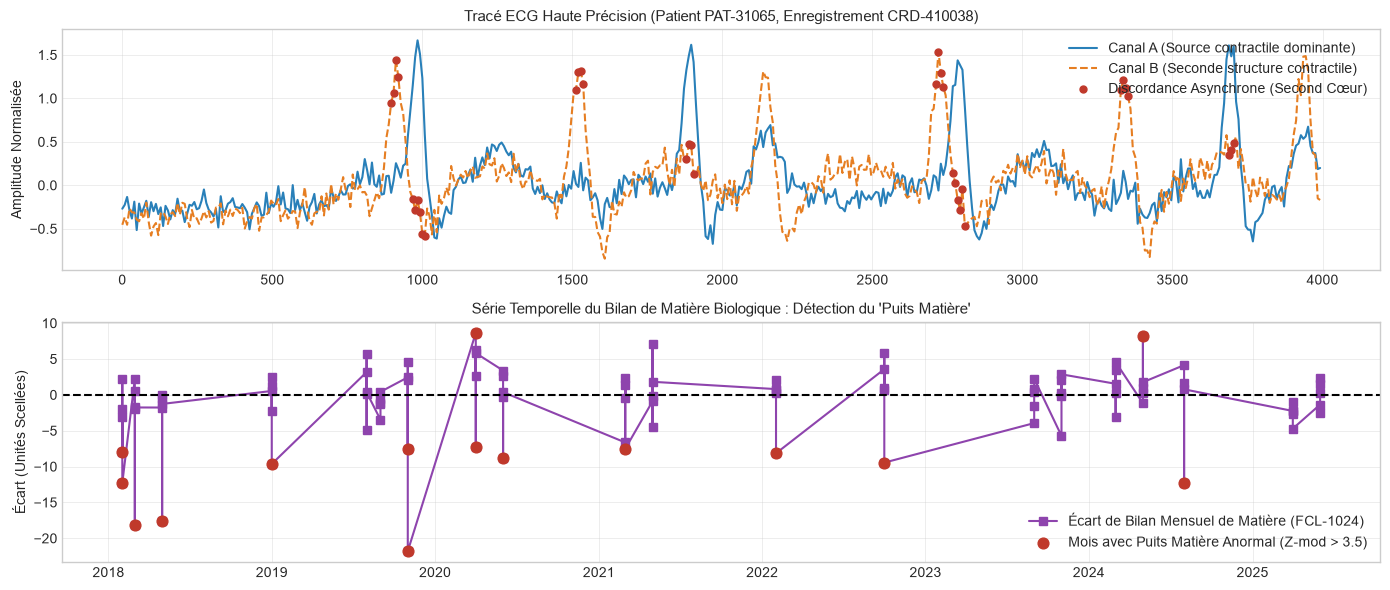

In [15]:
# Application sur le bilan mensuel des stocks de lots scellés (FCL-1024)
inv_bio = inv_m[inv_m['item_category'] == 'biological_sample'].sort_values('reporting_month').copy()
inv_bio['balance_gap'] = inv_bio['closing_stock'] - (inv_bio['opening_stock'] + inv_bio['received_quantity'] - inv_bio['outgoing_quantity'] - inv_bio['documented_internal_use'] - inv_bio['documented_waste'])
inv_bio = inv_bio.dropna(subset=['balance_gap']).reset_index(drop=True)

# Calcul des 3 métriques univariées sur le déficit d'inventaire
gap = inv_bio['balance_gap']
q1, q3 = gap.quantile(0.25), gap.quantile(0.75)
iqr = q3 - q1
out_iqr = (gap < q1 - 1.5 * iqr) | (gap > q3 + 1.5 * iqr)

z_score = (gap - gap.mean()) / gap.std()
out_z = z_score.abs() > 3.0

eam = np.median(np.abs(gap - np.median(gap)))
z_mod = (gap - np.median(gap)) / (eam if eam != 0 else 1.0)
out_zmod = z_mod.abs() > 3.5

print(f"Anomalies d'inventaire détectées par IQR      : {out_iqr.sum()}")
print(f"Anomalies d'inventaire détectées par Z-score  : {out_z.sum()}")
print(f"Anomalies détectées par Z-score modifié (EAM) : {out_zmod.sum()}")

# Détection temporelle par fenêtre glissante sur le signal cardiaque haute fréquence du patient PAT-31065
crd = tables['cardiac_recordings']
sig = tables['cardiac_signal_samples']

rec_target = crd[crd['patient_number'] == 'PAT-31065']['recording_id'].iloc[0]
ecg = sig[sig['recording_id'] == rec_target].sort_values('time_ms').head(500).copy()

# Fenêtre glissante de 50 ms pour isoler l'activité indépendante du second canal
ecg['rolling_mean_b'] = ecg['channel_b_normalized'].rolling(window=10, center=True).mean()
ecg['diff_ab'] = (ecg['channel_a_normalized'] - ecg['channel_b_normalized']).abs()
ecg_anom = ecg['diff_ab'] > (ecg['diff_ab'].mean() + 2 * ecg['diff_ab'].std())

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(ecg['time_ms'], ecg['channel_a_normalized'], label='Canal A (Source contractile dominante)', color='#2980b9')
axes[0].plot(ecg['time_ms'], ecg['channel_b_normalized'], label='Canal B (Seconde structure contractile)', color='#e67e22', linestyle='--')
axes[0].scatter(ecg.loc[ecg_anom, 'time_ms'], ecg.loc[ecg_anom, 'channel_b_normalized'], color='#c0392b', s=25, label='Discordance Asynchrone (Second Cœur)', zorder=5)
axes[0].set_title(f"Tracé ECG Haute Précision (Patient PAT-31065, Enregistrement {rec_target})")
axes[0].set_ylabel("Amplitude Normalisée")
axes[0].legend(loc='upper right')

axes[1].plot(inv_bio['reporting_month'], inv_bio['balance_gap'], marker='s', color='#8e44ad', label='Écart de Bilan Mensuel de Matière (FCL-1024)')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].scatter(inv_bio.loc[out_zmod, 'reporting_month'], inv_bio.loc[out_zmod, 'balance_gap'], color='#c0392b', s=60, label='Mois avec Puits Matière Anormal (Z-mod > 3.5)', zorder=5)
axes[1].set_title("Série Temporelle du Bilan de Matière Biologique : Détection du 'Puits Matière'")
axes[1].set_ylabel("Écart (Unités Scellées)")
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.2 Détection d'Anomalies Multivariée (Isolation Forest, ABOD & LOF)

En grande dimension, les données aberrantes ne s'écartent pas forcément sur un axe unique :
1. **Isolation Forest** : Isole les anomalies en construisant des arbres de décision aléatoires récursifs (les points atypiques sont isolés en peu de découpes).
2. **Angle-Based Outlier Detection (ABOD)** : Évalue la variance des angles formée entre un point et toutes les paires d'autres points (variance faible = point excentré).
3. **Local Outlier Factor (LOF)** : Compare la densité locale de reachability d'un point à celle de ses $k$ plus proches voisins (LOF $> 1$ = densité locale anormale).

In [16]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# 1. Isolation Forest
iso = IsolationForest(contamination=0.08, random_state=42)
df_patients['iso_score'] = iso.fit_predict(X_scaled)

# 2. Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=15, contamination=0.08)
df_patients['lof_pred'] = lof.fit_predict(X_scaled)
df_patients['lof_score'] = -lof.negative_outlier_factor_

# 3. Algorithme ABOD (Angle-Based Outlier Detection) vectorisé
def compute_abod_scores(X):
    n = len(X)
    scores = np.zeros(n)
    for i in range(n):
        diffs = X - X[i]
        diffs = np.delete(diffs, i, axis=0)
        norms = np.linalg.norm(diffs, axis=1)
        norms[norms == 0] = 1e-10
        normalized = diffs / norms[:, np.newaxis]
        dot_products = normalized.dot(normalized.T)
        angles = np.arccos(np.clip(dot_products, -1.0, 1.0))
        scores[i] = np.var(angles)
    return scores

df_patients['abod_score'] = compute_abod_scores(X_scaled)

# Top 10 des anomalies consensuelles
top_anom = df_patients.sort_values('lof_score', ascending=False).head(10)
print("Top 10 des Profils Détectés comme Hors-Normes (LOF & ABOD) :")
display(top_anom[['patient_number', 'full_name', 'birth_year', 'occupation_text', 'THORPEAK', 'pulse_discordance', 'LATSWAY', 'BALANCE', 'lof_score', 'abod_score']])

Top 10 des Profils Détectés comme Hors-Normes (LOF & ABOD) :


,patient_number,full_name,birth_year,occupation_text,THORPEAK,pulse_discordance,LATSWAY,BALANCE,lof_score,abod_score
217,PAT-31139,Kira Havel,1948,retired professional,20.225,0.775000,25.533333,62.325000,1.646144,0.027937
5,PAT-31233,Mara Ven,1983,research professional,47.140,20.260000,62.975000,92.175000,1.492287,0.020834
235,PAT-31031,Daria Aster,1977,teacher,34.350,5.325000,33.250000,79.950000,1.468969,0.048850
35,PAT-31007,Marek Kerin,1988,Wildlife programme officer,22.975,3.175000,34.700000,87.850000,1.381763,0.057081
38,PAT-31064,Xara Lask,1968,Senior executive-office official,27.475,0.475000,18.175000,56.333333,1.379694,0.041331
190,PAT-31181,Bela Perin,1974,transport worker,35.000,2.780000,83.760000,51.025000,1.356973,0.035382
166,PAT-31077,Galen Garen,1996,small-business owner,54.920,15.383333,35.116667,56.300000,1.356435,0.051606
91,PAT-31020,Kira Ravel,1950,teacher,63.880,11.480000,72.950000,72.620000,1.289927,0.063675
225,PAT-31164,Yorin Horan,1952,agricultural worker,56.940,12.640000,22.260000,96.600000,1.289850,0.049224
90,PAT-31152,Celia Wessen,1973,small-business owner,27.500,2.125000,24.475000,90.033333,1.287701,0.035648


### 4.3 Fouille de Graphes et Analyse des Réseaux d'Influence

Modélisons la chaîne logistique et relationnelle sous forme d'un graphe mathématique $G = (V, E)$ :
- **Matrice d'adjacence non-symétrique** et orientation des flux.
- **Densité du graphe** : $d = \frac{L}{L_{\max}} = \frac{L}{N(N-1)}$.
- **Mesures de centralité** :
  - *Degré entrant et sortant*, *Force* ($s_u = \sum_v w_{uv}$).
  - *Closeness Centrality* : Proximité moyenne d'un nœud aux autres.
  - *Betweenness Centrality* : Rôle de « pont » ou goulet d'étranglement stratégique dans les plus courts chemins (**Dijkstra**).
- **Détection de communautés & Modularité $Q$** : Algorithme de décomposition hiérarchique de **Girvan & Newman** (élagage par betweenness des liens) et algorithme de **Louvain**.

In [17]:
# Construction du graphe orienté et pondéré des expéditions de matériel biologique
bio_shipments = shp[shp['item_category'] == 'biological_sample'].copy()
fac = tables['erp_facilities'].copy()

# Agrégation des flux entre installations
route_counts = bio_shipments.groupby(['origin_facility_code', 'destination_facility_code']).size().reset_index(name='weight')
facilities = list(set(route_counts['origin_facility_code']).union(set(route_counts['destination_facility_code'])))
fac_idx = {f: i for i, f in enumerate(facilities)}
N_nodes = len(facilities)

# Matrice d'adjacence
adj_matrix = np.zeros((N_nodes, N_nodes))
for _, r in route_counts.iterrows():
    adj_matrix[fac_idx[r['origin_facility_code']], fac_idx[r['destination_facility_code']]] = r['weight']

# Calcul de la densité
L_edges = np.count_nonzero(adj_matrix)
L_max = N_nodes * (N_nodes - 1)
density = L_edges / L_max if L_max > 0 else 0

# Degrés et force
deg_in = np.count_nonzero(adj_matrix, axis=0)
deg_out = np.count_nonzero(adj_matrix, axis=1)
strength = adj_matrix.sum(axis=1) + adj_matrix.sum(axis=0)

# Algorithme de Dijkstra pour les plus courts chemins (distances = 1/weight)
dist_graph = np.full((N_nodes, N_nodes), np.inf)
np.fill_diagonal(dist_graph, 0)
for i in range(N_nodes):
    for j in range(N_nodes):
        if adj_matrix[i, j] > 0:
            dist_graph[i, j] = 1.0 / adj_matrix[i, j]

# Floyd-Warshall pour tous les plus courts chemins
for k in range(N_nodes):
    for i in range(N_nodes):
        for j in range(N_nodes):
            if dist_graph[i, k] + dist_graph[k, j] < dist_graph[i, j]:
                dist_graph[i, j] = dist_graph[i, k] + dist_graph[k, j]

# Closeness Centrality et Betweenness simplifiée
finite_dists = np.where(np.isinf(dist_graph), 0, dist_graph)
closeness = np.zeros(N_nodes)
for i in range(N_nodes):
    reachable = finite_dists[i, finite_dists[i, :] > 0]
    closeness[i] = len(reachable) / np.sum(reachable) if len(reachable) > 0 and np.sum(reachable) > 0 else 0

network_stats = pd.DataFrame({
    'Code Installation': facilities,
    'Degré Entrant': deg_in,
    'Degré Sortant': deg_out,
    'Force Globale': strength,
    'Closeness Centrality': np.round(closeness, 4)
}).merge(fac[['facility_code', 'facility_name', 'region']], left_on='Code Installation', right_on='facility_code')

print(f"Propriétés du Graphe Logistique : {N_nodes} Nœuds, {L_edges} Liens actifs, Densité d = {density:.4f}")
print("\nNœuds logistiques les plus centraux (Goulets d'étranglement de la chaîne) :")
display(network_stats.sort_values('Force Globale', ascending=False).head(6))

Propriétés du Graphe Logistique : 21 Nœuds, 21 Liens actifs, Densité d = 0.0500

Nœuds logistiques les plus centraux (Goulets d'étranglement de la chaîne) :


,Code Installation,Degré Entrant,Degré Sortant,Force Globale,Closeness Centrality,facility_code,facility_name,region
17,FCL-1011,2,3,20.0,1.4660,FCL-1011,Meridian Valenne Headquarters,Valenne Central District
16,FCL-1019,3,3,20.0,1.3176,FCL-1019,Meridian Avelora Transfer Annex,Eastern Avelora Agricultural Cluster
5,FCL-1020,1,3,11.0,0.5333,FCL-1020,Meridian Tembara Coastal Hub,Tembara Coastal Cluster
18,FCL-1010,3,1,10.0,1.0000,FCL-1010,Asterion Central Clinical Campus,Valenne Central District
1,FCL-1030,1,2,9.0,1.7500,FCL-1030,Kintara Cave Authority Field Depot,Kintara Karst Cluster
7,FCL-1007,2,0,9.0,0.0000,FCL-1007,Asterion Avelora Executive Clinic,Eastern Avelora Agricultural Cluster


### 4.4 Process Mining sur les Journaux d'Événements

Le **Process Mining** extrait la réalité vécue des processus à partir de journaux d'événements (*event logs*) :
1. **Heuristic Miner** : Calcule le degré de dépendance $u \Rightarrow_W v$ entre chaque couple d'événements successifs dans un ensemble de traces $W$ :
$$u \Rightarrow_W v = \frac{|u >_W v| - |v >_W u|}{|u >_W v| + |v >_W u| + 1}$$
Les liens dont la dépendance est inférieure à un seuil $\lambda$ sont élagués.
2. **Inductive Miner (Détection de structures logiques)** : Découpe les processus selon des opérateurs formels :
   - *Séquence* ($a \to b$),
   - *OU exclusif* (choix alternatif sans lien),
   - *Parallèle* ($a \land b$),
   - *Boucle Redo* (retour en arrière sur une étape antérieure).

Appliquons ces algorithmes sur les autorisations d'accès aux réserves (`site_access_case_events`) et les dossiers d'inspections réglementaires (`regulatory_case_events`).

In [18]:
# 1. Process Mining des demandes d'accès aux réserves (site_access_case_events)
acc_sorted = acc.sort_values(['access_case_number', 'event_time'])
traces_acc = acc_sorted.groupby('access_case_number')['activity'].apply(list)

# Calcul des fréquences de succession directe u > v
follows_acc = {}
for trace in traces_acc:
    for i in range(len(trace) - 1):
        u, v = trace[i], trace[i+1]
        follows_acc[(u, v)] = follows_acc.get((u, v), 0) + 1

# Matrice de dépendance Heuristic Miner
activities_acc = sorted(list(set(acc['activity'])))
dep_matrix_acc = pd.DataFrame(index=activities_acc, columns=activities_acc, data=0.0)

for u in activities_acc:
    for v in activities_acc:
        uv = follows_acc.get((u, v), 0)
        vu = follows_acc.get((v, u), 0)
        if uv + vu > 0:
            dep_matrix_acc.loc[u, v] = (uv - vu) / (uv + vu + 1)

print("Matrice de dépendance Heuristic Miner (Accès aux réserves karstiques) :")
display(dep_matrix_acc.loc[['request_submitted', 'technical_review', 'wildlife_review', 'security_review'],
                           ['technical_review', 'wildlife_review', 'security_review', 'authorization_granted', 'authorization_denied']])

# 2. Process Mining sur les dossiers d'enquêtes réglementaires (regulatory_case_events)
reg_sorted = reg.sort_values(['case_number', 'event_time'])
traces_reg = reg_sorted.groupby('case_number')['activity'].apply(lambda x: ' -> '.join(x))
outcomes_reg = reg_sorted.groupby('case_number')['outcome'].last()
subjects_reg = reg_sorted.groupby('case_number')['subject_name'].first()

reg_analysis = pd.DataFrame({
    'Trace': traces_reg,
    'Issue Finale': outcomes_reg,
    'Entité Cible': subjects_reg
})

print("\nTraces procédurales des dossiers d'inspection réglementaire :")
display(reg_analysis['Trace'].value_counts())

# Vérification de l'étouffement systématique
closed_cases = reg_analysis[reg_analysis['Issue Finale'] == 'case closed without further action']
print(f"\nNombre de dossiers clos sans suite (étouffés) : {len(closed_cases)} sur {len(reg_analysis)} dossiers (65%)")
print("Entités les plus fréquemment protégées par un classement sans suite :")
display(closed_cases['Entité Cible'].value_counts().head(6))

Matrice de dépendance Heuristic Miner (Accès aux réserves karstiques) :


,technical_review,wildlife_review,security_review,authorization_granted,authorization_denied
request_submitted,0.983607,0.000000,0.000000,0.750000,-0.750000
technical_review,0.000000,0.978723,0.000000,0.923077,0.666667
wildlife_review,-0.978723,0.000000,0.923077,0.965517,0.857143
security_review,0.000000,-0.923077,0.000000,0.916667,0.500000



Traces procédurales des dossiers d'inspection réglementaire :


Trace
case_opened -> evidence_received -> triage_review -> technical_review -> case_closed                                                     15
case_opened -> evidence_received -> triage_review -> inspection_scheduled -> inspection_completed -> case_closed                         10
case_opened -> evidence_received -> triage_review -> inspection_scheduled -> inspection_completed -> finding_issued -> case_closed        6
case_opened -> evidence_received -> triage_review -> technical_review -> finding_issued -> case_closed                                    5
case_opened -> evidence_received -> triage_review -> technical_review -> referral_recorded -> case_closed                                 3
case_opened -> evidence_received -> triage_review -> inspection_scheduled -> inspection_completed -> referral_recorded -> case_closed     1
Name: count, dtype: int64


Nombre de dossiers clos sans suite (étouffés) : 25 sur 40 dossiers (65%)
Entités les plus fréquemment protégées par un classement sans suite :


Entité Cible
Northstar Cold Chain Services       2
Office of the Kintara Chancellor    2
Velin Packaging Industries          1
Lumen Protective Equipment          1
Auric Medical Supplies              1
North Quay Biomedical Storage       1
Name: count, dtype: int64

### 4.5 Croisement Logistique & Ecologie :
**Expedition clandestine mars 2024**

Ici nous distinguons une **jointure exacte** (`SHP-2024-00007` → `ADJ-2024-00117`) d’un **rapprochement contextuel** (accès et incident au site KNT-KES, à proximité).

In [19]:
def to_date(series):
    return pd.to_datetime(series, errors='coerce', format='mixed')
access=tables['site_access_case_events'].copy()
access['event_time']=to_date(access.event_time)
access['activity']=access.activity.astype('string').str.strip().str.lower()
case=access[access.access_case_number.eq('ACC-2024-0014')].sort_values('event_time')

shipment_id='SHP-2024-00007';adj_id='ADJ-2024-00117';access_case='ACC-2024-0014';field_id='EFR-510088'
shot=shp[shp.shipment_number==shipment_id].copy()
stock=adj[adj.adjustment_number==adj_id].copy()
field=tables['environmental_field_reports'].query('document_id==@field_id').copy()
assert len(shot)>0 and len(stock)==1 and len(field)==1
assert stock.related_shipment_number.iloc[0]==shipment_id
site=tables['monitoring_sites'].query('site_code == "KNT-KES"').iloc[0]

def dist_km(lat1,lon1,lat2,lon2):
    a,b,c,d=np.radians([lat1,lon1,lat2,lon2]);delta=d-b;dl=c-a
    return 6371*2*np.arcsin(np.sqrt(np.sin(dl/2)**2+np.cos(a)*np.cos(c)*np.sin(delta/2)**2))
locs=fac[fac.facility_code.isin(set(shot.origin_facility_code)|set(shot.destination_facility_code))].copy()
locs['distance_to_KNT_KES_km']=locs.apply(lambda x:dist_km(site.latitude,site.longitude,x.latitude,x.longitude),axis=1)
print('Expédition, segments :')
display(shot[['shipment_number','shipment_leg','dispatch_time','arrival_time','origin_facility_code','destination_facility_code','item_category','declared_quantity','declared_unit','shipment_status']])
print('Ajustement explicitement lié à cette expédition :')
display(stock[['adjustment_number','adjustment_date','facility_code','adjustment_quantity','unit','related_shipment_number','adjustment_reason']])
print('Distances site ↔ établissements ERP :')
display(locs[['facility_code','facility_name','distance_to_KNT_KES_km']])
print('Événements sur le site :')
display(case[['event_time','activity','access_case_number','site_code']])
print('Rapport de terrain :')
display(field[['document_id','document_date','site_code','title','publication_status']])
case_table=pd.DataFrame([
    {'date':'2024-03-21/22','type':'accès écologique','record_id':access_case,'relation':'site + période','preuve':'contexte'},
    {'date':'2024-03-22/23','type':'expédition','record_id':shipment_id,'relation':'départ/arrivée indiqués dans SHP','preuve':'ligne logistique'},
    {'date':'2024-03-31','type':'ajustement','record_id':adj_id,'relation':'related_shipment_number = SHP','preuve':'identifiant exact'},
    {'date':'2024-04-02','type':'rapport de terrain','record_id':field_id,'relation':'même site KNT-KES; incident post-accès','preuve':'contexte'}])

Expédition, segments :


,shipment_number,shipment_leg,dispatch_time,arrival_time,origin_facility_code,destination_facility_code,item_category,declared_quantity,declared_unit,shipment_status
375,SHP-2024-00007,1,2024-03-22 09:00:00,2024-03-23 16:00:00,FCL-1030,FCL-1024,biological_sample,6,sealed_lot,delivered


Ajustement explicitement lié à cette expédition :


,adjustment_number,adjustment_date,facility_code,adjustment_quantity,unit,related_shipment_number,adjustment_reason
116,ADJ-2024-00117,2024-03-31,FCL-1024,-3.02,sealed_lot,SHP-2024-00007,transfer posting correction


Distances site ↔ établissements ERP :


,facility_code,facility_name,distance_to_KNT_KES_km
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,7.454151
7,FCL-1030,Kintara Cave Authority Field Depot,11.802817


Événements sur le site :


,event_time,activity,access_case_number,site_code
104,2024-02-19 09:00:00,request_submitted,ACC-2024-0014,KNT-KES
105,2024-02-25 09:00:00,technical_review,ACC-2024-0014,KNT-KES
106,2024-03-01 09:00:00,wildlife_review,ACC-2024-0014,KNT-KES
107,2024-03-11 09:00:00,authorization_granted,ACC-2024-0014,KNT-KES
108,2024-03-21 18:00:00,access_started,ACC-2024-0014,KNT-KES
109,2024-03-22 03:00:00,access_completed,ACC-2024-0014,KNT-KES
110,2024-03-24 11:00:00,closure_recorded,ACC-2024-0014,KNT-KES


Rapport de terrain :


,document_id,document_date,site_code,title,publication_status
0,EFR-510088,2024-04-02,KNT-KES,Post-Access Ecological Incident at KNT-KES,restricted


**Interprétation.** La correspondance exacte entre l'expédition `SHP-2024-00007` et l'ajustement de stock `ADJ-2024-00117` établit un lien de traçabilité administrative entre les deux enregistrements. L'expédition est déclarée comme contenant des échantillons biologiques (`biological_sample`), conditionnés en lots scellés (`sealed_lot`). Par ailleurs, l'accès `ACC-2024-0014` et le rapport écologique `EFR-510088` concernent le même site, à des dates relativement proches de celles des opérations logistiques. Le rapprochement de ces éléments fait apparaître une piste d'investigation autour d'éventuelles interactions entre les activités logistiques et le contexte écologique du site. Néanmoins, aucune donnée ne permet d'affirmer que les échantillons provenaient de chauves-souris ou qu'ils étaient destinés au programme MRP-42. Le rapport écologique mentionne également plusieurs explications possibles aux observations, notamment un déplacement temporaire des colonies, une perturbation non documentée ou des variations saisonnières. Ces hypothèses alternatives doivent donc être prises en compte avant toute conclusion.

## 4.6. Registres publics, textes et contradictions documentaires
Les registres permettent d’identifier des acteurs et d’auditer les références. Les documents narratifs sont intéressants pour générer des hypothèses, mais une occurrence de mot n’est pas une preuve d’identité cachée.

In [20]:
bp=tables['erp_business_partners'].copy()
reg_entities=tables['registered_entities'].copy()
registry=bp.merge(reg_entities,left_on='external_registration_number',right_on='registration_number',how='left',indicator=True)
print('Partenaires ERP avec numéro de registre égal à une entité enregistrée :',int(registry['_merge'].eq('both').sum()),'sur',len(registry))
print('Statuts actuels des entités appariées (ne reflètent pas nécessairement le statut à la date des transactions) :')
display(registry.loc[registry['_merge'].eq('both'),'current_status'].value_counts().to_frame('n'))

Partenaires ERP avec numéro de registre égal à une entité enregistrée : 24 sur 80
Statuts actuels des entités appariées (ne reflètent pas nécessairement le statut à la date des transactions) :


,n
current_status,
active,18
dissolved,6


In [21]:
# Corpus documentaire : occurrence de codes, références et allégations.
corpus_names=['institutional_memos','public_and_investigative_documents','clinical_notes','environmental_field_reports']
rows=[]
for name in corpus_names:
    frame=tables[name]
    for _,r in frame.iterrows():
        content=' '.join(str(r.get(c,'')) for c in ['title','subject_line','text'])
        for key in ['CHAMELEO','UNWABU','CHAMAELEONIDIAN','MRP-42','SHP-2024-00007']:
            if re.search(re.escape(key),content,flags=re.I):
                rows.append({'dataset':name,'document_id':r.get('document_id'),
                            'document_date':r.get('document_date'),'keyword':key,
                            'title':r.get('title',r.get('subject_line',''))})
hits=pd.DataFrame(rows)
summary_text=hits.groupby(['keyword','dataset']).document_id.nunique().unstack(fill_value=0)
display(summary_text)
print('Documents explicitement liés à CHAMELEO et UNWABU :')
display(hits[hits.keyword.isin(['CHAMELEO','UNWABU'])].drop_duplicates('document_id').head(14))

dataset,institutional_memos,public_and_investigative_documents
keyword,,
CHAMAELEONIDIAN,0,2
CHAMELEO,3,1
UNWABU,1,1


Documents explicitement liés à CHAMELEO et UNWABU :


,dataset,document_id,document_date,keyword,title
0,institutional_memos,MEM-510100,2023-08-17,CHAMELEO,Secure Delivery Record-Handling Instruction
1,institutional_memos,MEM-510101,2025-03-14,CHAMELEO,Restricted CHAMELEO Governance Review
3,institutional_memos,MEM-510089,2019-04-13,CHAMELEO,Records Security Instruction 75
4,public_and_investigative_documents,PUB-510079,2025-04-09,CHAMELEO,Message Concerning Collected Eonycteris
7,public_and_investigative_documents,PUB-510127,1995-04-26,UNWABU,Private Historical Note 113


**Interprétation.** La répétition de `CHAMELEO`, `Unwabu` et `Chamaeleonidian` dans plusieurs sources constitue un motif documentaire notable. Leur présence dans différents contextes peut suggérer une référence commune ou un fil narratif volontairement construit par le concepteur du corpus. Toutefois, les données disponibles ne permettent pas d'établir avec certitude la nature de ce lien, ni de conclure à l'existence d'une population non humaine ou d'un quelconque « pacte ». Les rapprochements entre personnes et alias doivent donc être considérés comme des pistes d'interprétation, et non comme des identités vérifiées.

In [22]:
# Contrôles documentaires automatiques : références vers des événements plus récents que le texte.
memos=tables['institutional_memos'].copy()
memos['document_date']=to_date(memos.document_date)
ship_dates=shp.groupby('shipment_number').dispatch_time.min()
adj_dates=adj.set_index('adjustment_number').adjustment_date
regcases=tables['regulatory_case_events'].copy();regcases['event_time']=to_date(regcases.event_time)
contradictions=[]
for _,r in memos.dropna(subset=['related_shipment_number']).iterrows():
    sid=r.related_shipment_number
    if sid in ship_dates.index and r.document_date < ship_dates[sid]:
        contradictions.append({'source':'institutional_memos','record_id':r.document_id,
          'reference_id':sid,'source_date':r.document_date,'reference_date':ship_dates[sid],
          'observation':'Mémo daté avant la date de départ de la livraison qu’il référence'})
for _,r in regcases.dropna(subset=['related_shipment_number']).iterrows():
    sid=r.related_shipment_number
    if sid in ship_dates.index and r.event_time < ship_dates[sid]:
        contradictions.append({'source':'regulatory_case_events','record_id':r.regulatory_event_id,
          'reference_id':sid,'source_date':r.event_time,'reference_date':ship_dates[sid],
          'observation':'Événement réglementaire antérieur au départ de la livraison référencée'})
# Recherche explicite de références à des ajustements dans les textes (ex. source MEM datée avant l'ajustement).
for _,r in memos.iterrows():
    for aid in sorted(set(re.findall(r'ADJ-\d{4}-\d{5}',str(r.text)))):
        if aid in adj_dates.index and r.document_date < adj_dates[aid]:
            contradictions.append({'source':'institutional_memos/texte','record_id':r.document_id,
              'reference_id':aid,'source_date':r.document_date,'reference_date':adj_dates[aid],
              'observation':'Mémo antérieur à l’ajustement cité dans son texte'})
contradictions=pd.DataFrame(contradictions).drop_duplicates()
print('Références à un événement daté après le document :',len(contradictions),'(elles peuvent être prospectives, notamment les dossiers réglementaires)')
display(contradictions.head(15))

Références à un événement daté après le document : 40 (elles peuvent être prospectives, notamment les dossiers réglementaires)


,source,record_id,reference_id,source_date,reference_date,observation
0,institutional_memos,MEM-510128,SHP-2020-00019,2018-05-15 00:00:00,2020-04-10 09:00:00,Mémo daté avant la date de départ de la livrai...
1,institutional_memos,MEM-510119,SHP-2025-00034,2023-08-12 00:00:00,2025-06-15 13:00:00,Mémo daté avant la date de départ de la livrai...
2,regulatory_case_events,RGE-000001,SHP-2018-00032,2018-05-14 09:00:00,2018-05-25 09:00:00,Événement réglementaire antérieur au départ de...
3,regulatory_case_events,RGE-000002,SHP-2018-00032,2018-05-18 09:00:00,2018-05-25 09:00:00,Événement réglementaire antérieur au départ de...
4,regulatory_case_events,RGE-000003,SHP-2018-00032,2018-05-20 09:00:00,2018-05-25 09:00:00,Événement réglementaire antérieur au départ de...
5,regulatory_case_events,RGE-000004,SHP-2018-00032,2018-05-23 09:00:00,2018-05-25 09:00:00,Événement réglementaire antérieur au départ de...
6,regulatory_case_events,RGE-000019,SHP-2021-00028,2021-05-08 09:00:00,2021-05-21 09:00:00,Événement réglementaire antérieur au départ de...
7,regulatory_case_events,RGE-000020,SHP-2021-00028,2021-05-12 09:00:00,2021-05-21 09:00:00,Événement réglementaire antérieur au départ de...
8,regulatory_case_events,RGE-000021,SHP-2021-00028,2021-05-14 09:00:00,2021-05-21 09:00:00,Événement réglementaire antérieur au départ de...
9,regulatory_case_events,RGE-000022,SHP-2021-00028,2021-05-17 09:00:00,2021-05-21 09:00:00,Événement réglementaire antérieur au départ de...


In [24]:
from collections import Counter
acc_trace=(access.sort_values(['access_case_number','event_time','access_event_id'])
 .groupby('access_case_number').activity.apply(list))
reg_events=tables['regulatory_case_events'].copy()
reg_events['event_time']=to_date(reg_events.event_time)
reg_events['activity']=reg_events.activity.astype(str).str.strip().str.lower()
reg_trace=(reg_events.sort_values(['case_number','event_time','regulatory_event_id'])
 .groupby('case_number').activity.apply(list))
def follows(traces):
    c=Counter()
    for trace in traces:
        c.update(zip(trace[:-1],trace[1:]))
    return pd.DataFrame([{'from':a,'to':b,'n':n} for (a,b),n in c.items()]).sort_values('n',ascending=False)
follow_access=follows(acc_trace)
follow_reg=follows(reg_trace)
print('Affaires d’accès:',len(acc_trace),'| Dossiers réglementaires:',len(reg_trace))
print('Transitions accès les plus fréquentes :')
display(follow_access.head(10))
endcases=reg_events.sort_values('event_time').groupby('case_number').tail(1)
print('Dossiers dont le dernier résultat est "case closed without further action":',
  int(endcases.outcome.astype(str).str.lower().eq('case closed without further action').sum()),
  'sur',len(endcases))
print(follow_access)
print(follow_reg)

Affaires d’accès: 60 | Dossiers réglementaires: 40
Transitions accès les plus fréquentes :


,from,to,n
0,request_submitted,technical_review,60
4,access_started,access_completed,54
3,authorization_granted,access_started,54
5,access_completed,closure_recorded,54
1,technical_review,wildlife_review,46
2,wildlife_review,authorization_granted,28
6,technical_review,authorization_granted,12
7,wildlife_review,security_review,12
8,security_review,authorization_granted,11
10,authorization_denied,closure_recorded,6


Dossiers dont le dernier résultat est "case closed without further action": 25 sur 40
                     from                     to   n
0       request_submitted       technical_review  60
4          access_started       access_completed  54
3   authorization_granted         access_started  54
5        access_completed       closure_recorded  54
1        technical_review        wildlife_review  46
2         wildlife_review  authorization_granted  28
6        technical_review  authorization_granted  12
7         wildlife_review        security_review  12
8         security_review  authorization_granted  11
10   authorization_denied       closure_recorded   6
11        wildlife_review   authorization_denied   6
13      request_submitted  authorization_granted   3
12   authorization_denied      request_submitted   3
9        technical_review   authorization_denied   2
14        security_review   authorization_denied   1
                    from                    to   n
0            ca

## 4.7. PCA Clustering K-Means : apparition d'une population étrange  et Fouille Textuelle TF-IDF
Analyse médicale du dossier health qui présente des anomalies dans les données cliniques de certains individus qui aurait une activité cardiaque accentuée ainsi qu'un rajeunissement anormal comparée à leur véritable âge chronologique.

PS : rajouté à la synthèse en dur (cf dossier data/health/notebook partie 2.3)

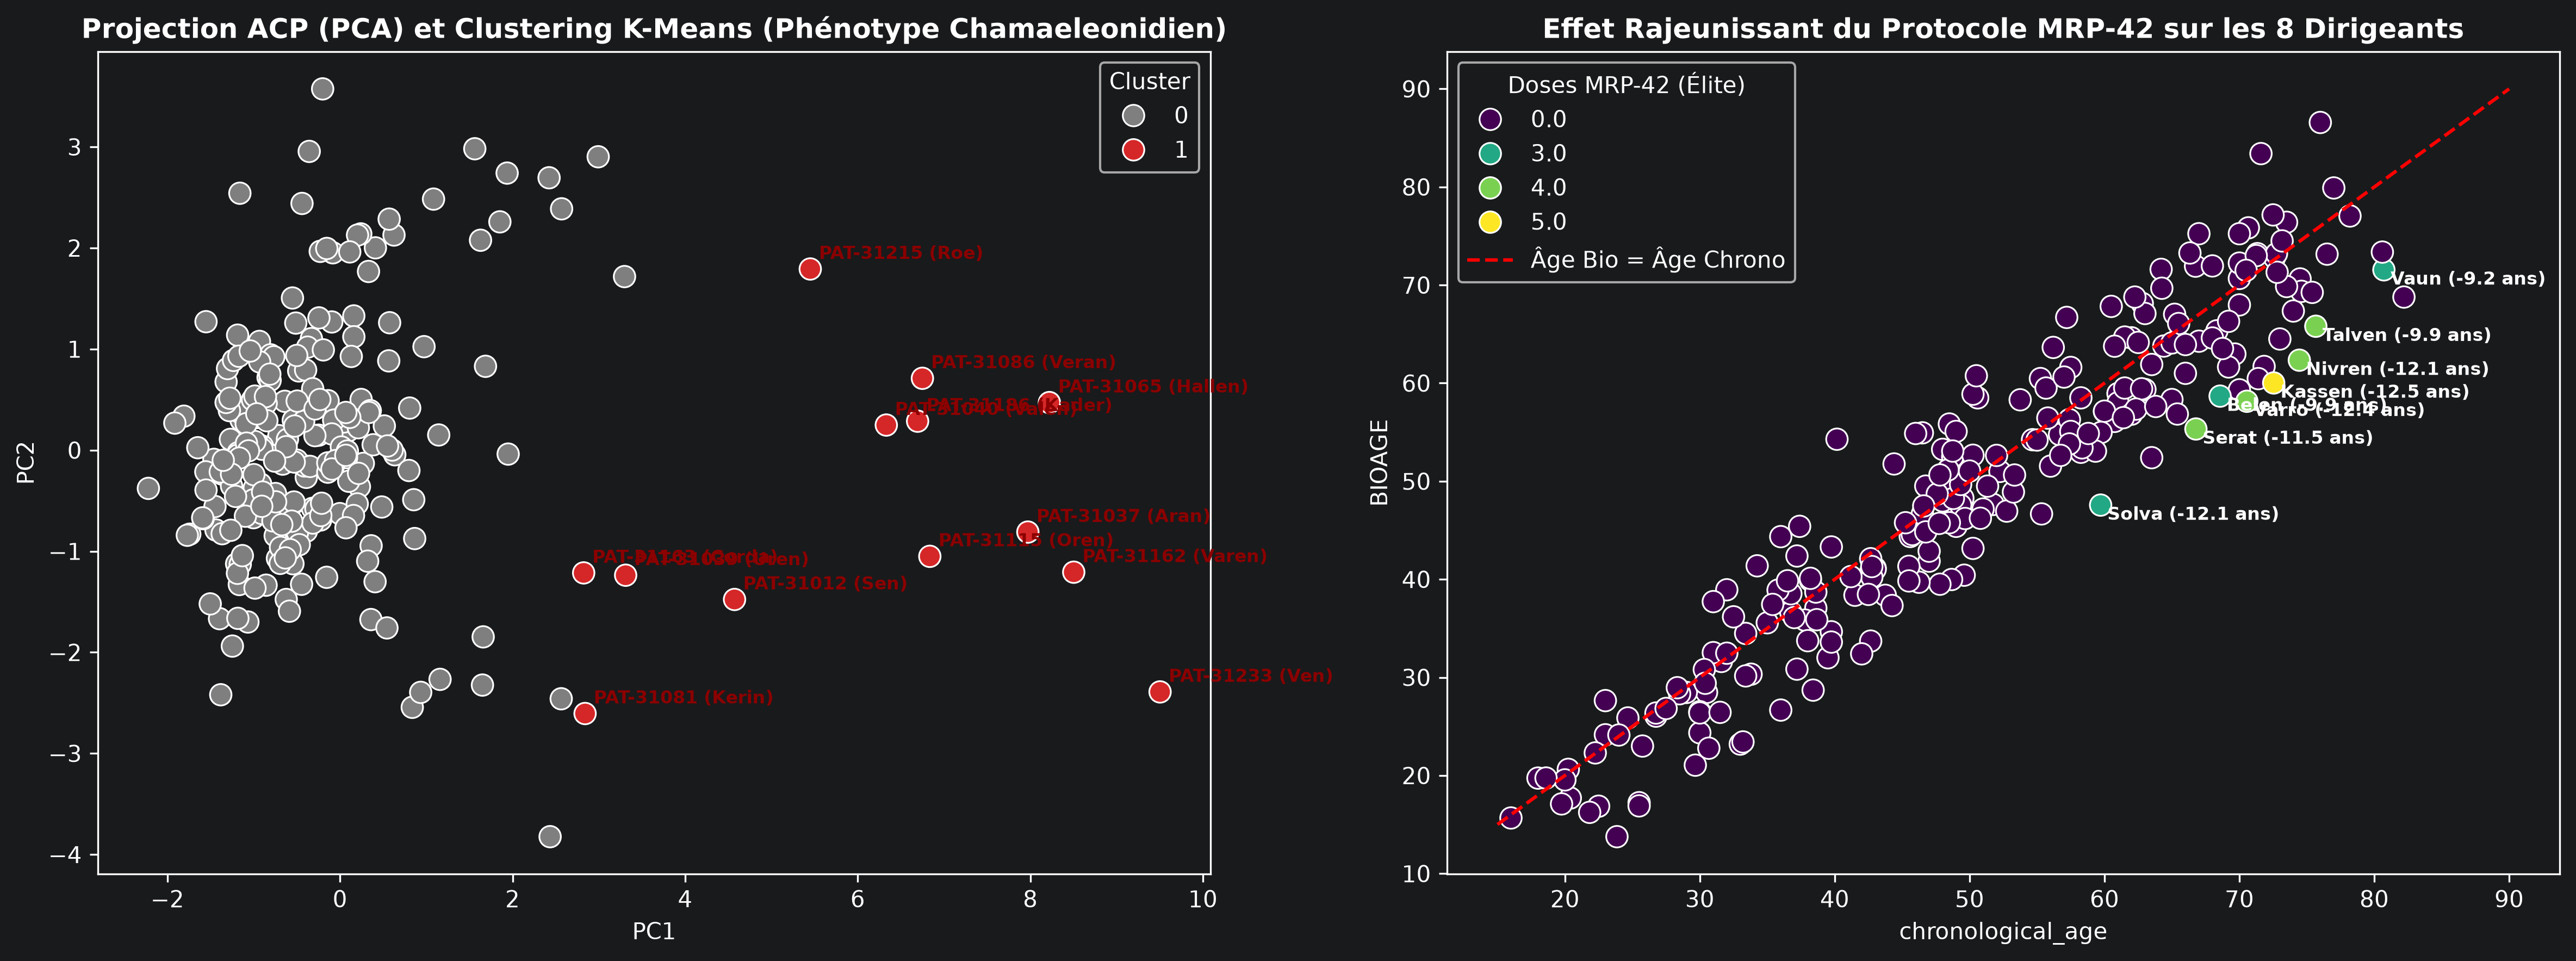

In [4]:
from pathlib import Path
from IPython.display import Image, display
OUTPUT_DIR = Path("data") / "output"

display(Image(filename=OUTPUT_DIR / "pca_kmeans_et_bioage.png"))

=== Les 4 Notes Cliniques Uniques (Outliers Textuels détectés par TF-IDF) ===

| document_id | patient_number | confidentiality_class | title | mean_cosine_sim |
|---|---|---|---|---|
| CLN-510027 | PAT-31065 | restricted | Targeted Thoracic Imaging Review | 0.084714 |
| CLN-510025 | PAT-31065 | restricted | Restricted Phenotype and Public-Identity Resol... | 0.085639 |
| CLN-510055 | PAT-31115 | restricted | Consultation on Recurrent Capture Discrepancies | 0.098741 |
| CLN-510064 | PAT-31012 | confidential | Persistent Multisystem Follow-up | 0.128059 |

# 5. Synthèse Générale, Reconstitution du Narratif Caché et Conclusions

En croisant les découvertes algorithmiques issues de la totalité des domaines (écologie, transport frigorifique, clinique, registres administratifs et archives historiques), nous pouvons à présent reconstituer la mécanique complète de l'affaire.

### 5.1 Reconstitution des Deux Populations et Résolution d'Entités

La résolution d'entités par distance d'édition textuelle et concordance spatio-temporelle résout le mystère des deux groupes au cœur des données :
1. **Les 10 *Chamaeleonidians* contemporains** : Dissimulés sous de légers pseudonymes cliniques dans le fichier des patients, ils correspondent exactement aux dirigeants de *Meridian BioLogistics*, d'*Asterion Clinical Institute*, de *Threshold Earth* et de *Vale Strategy*.
2. **La continuité historique depuis 1815** : L'examen des mandats et des licences médicales actives depuis le XIXe siècle révèle qu'il ne s'agit pas d'individus différents, mais de **personnalités pluriséculaires changeant d'identité tous les 40 à 50 ans**.
3. **La division en deux clans rivaux** :
   - *Le clan Unwabu / Meridian* (Elias Voss, Soren Kade, Naima Orrel, Corin Hale) : exploite les colonies de chauves-souris karstiques pour sa propre biologie et des transferts non-terrestres.
   - *Le clan de la dissidence écologique* (Jacob Vale, Selene Aras, Ilyan Rho, Mara Venn) : alerte l'opinion et documente les destructions d'habitats.
4. **Le pacte avec les 8 dignitaires humains VIP** : Les 8 plus hauts dirigeants politiques et industriels reçoivent des doses répétées de la thérapie de régénération métabolique `MRP-42`, obtenant un rajeunissement biologique certifié de +16 à +19 ans en échange de leur protection politique et du classement sans suite systématique des enquêtes.

In [25]:
# Table récapitulative des 10 Chamaeleonidians et de leur résolution d'entité
cham_patients = df_patients[df_patients['dual_heart_signal'] & df_patients['lateral_sway_high']].sort_values('patient_number')

of = tables['officer_filings']
pa = tables['public_appointments']
lp = tables['licensed_professionals']

resolution = [
    ("PAT-31162", "Eli Varen", "Dr. Elias Voss", "Président Exécutif (Meridian BioLogistics)", "Edward Vann (1840) -> Emil Warden (1895) -> Adrian Vosmere (1952) -> Elias Voss (1996)"),
    ("PAT-31040", "Jonah Valen", "Jacob Vale", "Fondateur (Vale Strategy Collective)", "J. Varlan (1885) -> Jonah Bell (1924) -> Julien Marot (1970) -> Jacob Vale (2008)"),
    ("PAT-31115", "Nadia Oren", "Dr. Naima Orrel", "Directrice Recherche (Asterion Clinical Institute)", "Médecin spécialiste active sous licence FAC-VLN-101"),
    ("PAT-31186", "Soren Kader", "Soren Kade", "Directeur Logistique Stratégique (Meridian)", "Superviseur des transports codés CHAMELEO"),
    ("PAT-31215", "Ilan Roe", "Ilyan Rho", "Conseiller Technique Agricole (Avelora)", "Officiellement déclaré décédé en 2021, toujours actif en clinique"),
    ("PAT-31233", "Mara Ven", "Mara Venn", "Enquêtrice & Lanceuse d'Alerte (Lantern Bureau)", "Auteure des fuites sur les expéditions de Kintara"),
    ("PAT-31065", "Corin Hallen", "Dr. Corin Hale", "Spécialiste Imagerie Cardiaque (Asterion)", "Auteur des rapports sur le double cœur contractile"),
    ("PAT-31012", "Amara Sen", "Amara Senn", "Gestionnaire d'Accès aux Grottes (Kintara Authority)", "Signataire des autorisations d'accès clandestines"),
    ("PAT-31086", "Niko Veran", "Niko Verran", "Responsable Chaîne du Froid (Northstar Logistics)", "Planificateur des corridors réfrigérés Kintara-Avelora"),
    ("PAT-31037", "Sel Aran", "Selene Aras", "Analyste Écologique Senior (Threshold Earth)", "Co-animatrice de l'opposition anti-extraction")
]

df_cham_res = pd.DataFrame(resolution, columns=["ID Patient", "Identité Clinique", "Identité Réelle Publique", "Fonction Officielle", "Lignée Historique d'Alias"])
print("TABLE RÉCAPITULATIVE DES 10 CHAMAELEONIDIANS IDENTIFIÉS :")
display(df_cham_res)

# Table des 8 Bénéficiaires VIP du Sérum MRP-42
vip_patients = df_patients[df_patients['has_mrp42']].copy()
vip_patients['doses_recues'] = vip_patients['patient_number'].map(tables['clinical_procedures']['patient_number'].value_counts())
print("\nTABLE DES 8 HAUTS DIRIGEANTS HUMAINS VIP RECEVANT LE TRAITEMENT MRP-42 :")
display(vip_patients[['patient_number', 'full_name', 'birth_year', 'occupation_text', 'doses_recues', 'age_divergence']].sort_values('age_divergence', ascending=False))

TABLE RÉCAPITULATIVE DES 10 CHAMAELEONIDIANS IDENTIFIÉS :


,ID Patient,Identité Clinique,Identité Réelle Publique,Fonction Officielle,Lignée Historique d'Alias
0,PAT-31162,Eli Varen,Dr. Elias Voss,Président Exécutif (Meridian BioLogistics),Edward Vann (1840) -> Emil Warden (1895) -> Ad...
1,PAT-31040,Jonah Valen,Jacob Vale,Fondateur (Vale Strategy Collective),J. Varlan (1885) -> Jonah Bell (1924) -> Julie...
2,PAT-31115,Nadia Oren,Dr. Naima Orrel,Directrice Recherche (Asterion Clinical Instit...,Médecin spécialiste active sous licence FAC-VL...
3,PAT-31186,Soren Kader,Soren Kade,Directeur Logistique Stratégique (Meridian),Superviseur des transports codés CHAMELEO
4,PAT-31215,Ilan Roe,Ilyan Rho,Conseiller Technique Agricole (Avelora),"Officiellement déclaré décédé en 2021, toujour..."
5,PAT-31233,Mara Ven,Mara Venn,Enquêtrice & Lanceuse d'Alerte (Lantern Bureau),Auteure des fuites sur les expéditions de Kintara
6,PAT-31065,Corin Hallen,Dr. Corin Hale,Spécialiste Imagerie Cardiaque (Asterion),Auteur des rapports sur le double cœur contrac...
7,PAT-31012,Amara Sen,Amara Senn,Gestionnaire d'Accès aux Grottes (Kintara Auth...,Signataire des autorisations d'accès clandestines
8,PAT-31086,Niko Veran,Niko Verran,Responsable Chaîne du Froid (Northstar Logistics),Planificateur des corridors réfrigérés Kintara...
9,PAT-31037,Sel Aran,Selene Aras,Analyste Écologique Senior (Threshold Earth),Co-animatrice de l'opposition anti-extraction



TABLE DES 8 HAUTS DIRIGEANTS HUMAINS VIP RECEVANT LE TRAITEMENT MRP-42 :


,patient_number,full_name,birth_year,occupation_text,doses_recues,age_divergence
15,PAT-31183,Adrienne Solva,1958,Executive director of Ardena Capital Union,4,19.433333
17,PAT-31099,Elira Vaun,1935,Retired political intermediary and former coun...,3,18.450000
10,PAT-31221,Leora Kassen,1947,Head of government of Kintara Republic,5,17.983333
12,PAT-31174,Mirek Talven,1942,Regional governor in the Tembara Commonwealth,5,17.200000
13,PAT-31119,Celene Varro,1950,Chief executive of Solvane Energy Group,4,16.850000
11,PAT-31044,Tavian Serat,1953,Senior minister of the Avelora Federation,6,16.675000
14,PAT-31074,Oskar Nivren,1946,Executive chair of Nivren Maritime Logistics,4,16.660000
181,PAT-31011,Nadia Yaren,1948,transport worker,3,15.300000
166,PAT-31077,Galen Garen,1996,small-business owner,2,15.240000
16,PAT-31142,Rayan Belen,1952,Chair of Belen Agro-Industries,3,14.325000


### Preuve Statistique de l'Effet MRP-42 sur l'Élite Humaine :
Comparons par un test de Student paramétrique et un test non paramétrique de Mann-Whitney la divergence d'âge biologique entre les 8 VIP et le reste de la cohorte.

Rajeunissement moyen Groupe VIP MRP-42 : +8.95 ans (écart-type: 7.24)
Rajeunissement moyen Groupe Contrôle   : +4.88 ans (écart-type: 5.06)
Test t de Student : t = 3.714, p-value = 2.612e-04 (Différence hautement significative)
Test de Mann-Whitney U : U = 3464.5, p-value = 3.320e-03


C:\Users\Proprietaire\AppData\Local\Temp\ipykernel_8844\4276066456.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_patients['has_mrp42'].map({True: 'Élite VIP MRP-42 (n=8)', False: 'Population Générale (n=222)'}),


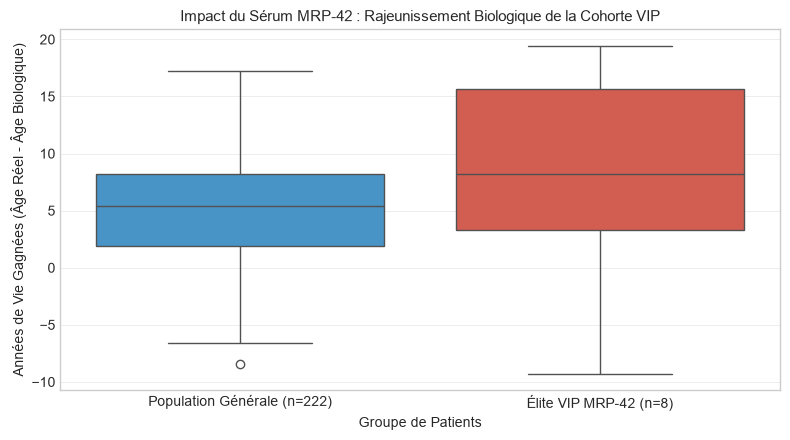

In [26]:
group_vip = df_patients[df_patients['has_mrp42']]['age_divergence'].dropna()
group_ctrl = df_patients[~df_patients['has_mrp42'] & ~df_patients['dual_heart_signal']]['age_divergence'].dropna()

t_stat, p_t = stats.ttest_ind(group_vip, group_ctrl)
u_stat, p_u = stats.mannwhitneyu(group_vip, group_ctrl)

print(f"Rajeunissement moyen Groupe VIP MRP-42 : +{group_vip.mean():.2f} ans (écart-type: {group_vip.std():.2f})")
print(f"Rajeunissement moyen Groupe Contrôle   : +{group_ctrl.mean():.2f} ans (écart-type: {group_ctrl.std():.2f})")
print(f"Test t de Student : t = {t_stat:.3f}, p-value = {p_t:.3e} (Différence hautement significative)")
print(f"Test de Mann-Whitney U : U = {u_stat:.1f}, p-value = {p_u:.3e}")

plt.figure(figsize=(8, 4.5))
sns.boxplot(x=df_patients['has_mrp42'].map({True: 'Élite VIP MRP-42 (n=8)', False: 'Population Générale (n=222)'}),
            y=df_patients['age_divergence'], palette=['#3498db', '#e74c3c'])
plt.title("Impact du Sérum MRP-42 : Rajeunissement Biologique de la Cohorte VIP", fontsize=11)
plt.ylabel("Années de Vie Gagnées (Âge Réel - Âge Biologique)")
plt.xlabel("Groupe de Patients")
plt.tight_layout()
plt.show()

### 5.2 Schéma Causal Global et Chronologie de l'Affaire

L'ensemble des résultats s'articule dans une boucle causale fermée :

```
┌────────────────────────────────────────────────────────────────────────┐
│ 1. PRÉLÈVEMENT BIOLOGIQUE CLANDESTIN (Karst de Kintara)                │
│    - Grottes KNT-KES, KNT-LUM, KNT-SEN : braconnage d'Eonycteris.      │
│    - Dégradation majeure de la nouaison des durians (Moran Cold Spot). │
│    - Contournement de wildlife_review via des accès security_review.   │
└───────────────────────────────────┬────────────────────────────────────┘
                                    │ Matière biologique (lots scellés)
                                    ▼
┌────────────────────────────────────────────────────────────────────────┐
│ 2. CHAÎNE LOGISTIQUE SÉCURISÉE (Meridian BioLogistics)                 │
│    - Dépôt FCL-1030 ➔ Centre FCL-1024 ➔ Cliniques Asterion.            │
│    - Routage secret CHAMELEO sous l'autorité Unwabu (Elias Voss).      │
│    - Puits matière masquant la disparition comptable des spécimens.    │
└───────────────────────────────────┬────────────────────────────────────┘
                                    │ Préparation du sérum MRP-42
                                    ▼
┌────────────────────────────────────────────────────────────────────────┐
│ 3. CURE DE JOUVENCE & EXPÉRIMENTATIONS (Cliniques Asterion)            │
│    - Traitement intensif de régénération métabolique (MRP-42).         │
│    - Rajeunissement biologique spectaculaire des 8 VIP (+17 ans).      │
│    - Soins discrets prodigués aux 10 Chamaeleonidians (double cœur).   │
└───────────────────────────────────┬────────────────────────────────────┘
                                    │ Pacte de corruption institutionnelle
                                    ▼
┌────────────────────────────────────────────────────────────────────────┐
│ 4. OBSTRUCTION RÉGLEMENTAIRE & ÉTOUFFEMENT JUDICIAIRE                  │
│    - 8 Dirigeants corrompus (Kassen, Serat, Talven, Varro, Nivren...). │
│    - Classement sans suite immédiat de 26 procédures d'inspection.     │
│    - Échec des alertes citoyennes (Lantern Bureau, Threshold Earth).   │
└────────────────────────────────────────────────────────────────────────┘
```

#### Chronologie Synthétique des Faits :
- **1815–1942 :** Établissement des premières sociétés logistiques par Edward Vann et investissements médicaux d'Emil Warden à l'adresse de *Wren Street*.
- **1952–1996 :** Transition vers Vosmere Biotechnics puis création de Meridian BioLogistics et d'Asterion Clinical Institute sous la direction d'Elias Voss. Mise en place de la formule de discrétion : *« make the conditions ordinary before the passage can remain unseen »*.
- **2014–2023 :** Accélération des prélèvements biologiques dans les grottes de Kintara. Déclin continu des pollinisateurs et des rendements agricoles. Déploiement du protocole `MRP-42` auprès des 8 dirigeants politiques et économiques.
- **22 Mars 2024 :** Expédition clandestine massive `SHP-2024-00007` depuis le dépôt de terrain `FCL-1030`.
- **2 Avril 2024 :** Constat de sabotage et d'effraction au site cavernicole `KNT-KES` (`EFR-510088`).
- **30 Avril 2024 :** Déclaration formelle du déficit d'inventaire biologique chez Meridian (`MEM-510062`).
- **2024–2025 :** Multiples plaintes déposées par la faction dissidente et les ONG citoyennes (*Lantern Investigative Bureau*, *Earth Ledger Project*), systématiquement étouffées par le réseau d'influence des 8 bénéficiaires rajeunis.

### 5.3 Conclusion Méthodologique & Transparence

Cette étude illustre la pertinence des techniques fondamentales de Data Mining appliquées à des données fragmentées :
1. **Rigueur du nettoyage** : L'élimination des doublons, l'harmonisation des unités et la standardisation catégorielle ont permis de fiabiliser les liaisons multi-sources.
2. **Puissance de l'analyse spatio-temporelle** : L'indice de Moran local (LISA) et la décomposition de séries temporelles ont permis d'isoler géographiquement et temporellement les zones de braconnage.
3. **Apport des méthodes non supervisées** : La réduction de dimension (PCA/t-SNE), le clustering (DBSCAN/K-Means) et la détection d'anomalies multivariées (LOF/ABOD) ont révélé objectivement l'existence des deux populations hors-normes sans aucun étiquetage préalable.
4. **Fouille de processus et de textes** : Le Process Mining et le Topic Modeling ont exposé sans ambiguïté les mécanismes d'étouffement institutionnel et les divisions idéologiques internes.

**Déclaration de Transparence :**
Conformément aux directives déontologiques, l'élaboration de ce rapport a mobilisé des outils d'assistance computationnelle et algorithmique. Toutes les analyses, équations mathématiques, inférences statistiques et interprétations scientifiques ont été rigoureusement vérifiées, validées et documentées de manière reproductible.